# StegMorph novelty programme: GPU pipeline notebook (Mac M-series, PyTorch MPS)
All steps after E10/E11 run here and every output is stored in this notebook. Kernel: `StegMorph (py3.14, MPS)`.
Integrity rules (plan sec. 1): only logged numbers, claims pre-registered in `state/CLAIMS.md`, subject-level splits, >=3 seeds, nulls reported. **No terminal state is set by this notebook.**
Sections: 0 environment/GPU check - 1 data inventory - 2 OASIS subject-disjoint splits (JPEG caveat) - 3 result tables E9/E10/E11 with the pre-registered rules - 4 figures for the paper - 5 transfer experiments (GPU).

In [1]:
import os, sys, json, glob, time, hashlib, platform, numpy as np, torch
ROOT = os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
os.chdir(ROOT); sys.path.insert(0, os.path.join(ROOT, "code")); sys.path.insert(0, ROOT)
print("root", ROOT); print("python", sys.version.split()[0], "| torch", torch.__version__, "| platform", platform.platform())
dev = torch.device("mps" if torch.backends.mps.is_available() else "cpu"); print("device:", dev, "| MPS available:", torch.backends.mps.is_available())
x = torch.randn(2048, 2048, device=dev); y = x @ x; (torch.mps.synchronize() if dev.type == "mps" else None)
t = time.time(); [x @ x for _ in range(20)]; (torch.mps.synchronize() if dev.type == "mps" else None); print("20 matmuls 2048^2 on", dev, round(time.time()-t, 3), "s")

root <PROJECT_ROOT>
python 3.14.5 | torch 2.15.0 | platform macOS-27.0.1-arm64-arm-64bit-Mach-O
device: mps | MPS available: True


20 matmuls 2048^2 on mps 0.14 s


## 1. Data inventory (all from files on disk)

In [2]:
man = json.load(open("data/splits/ixi_split_manifest.json"))
for k, v in man.items(): print("IXI", k, {a: b for a, b in v.items() if a != "sha256"}, v["sha256"][:12])
O = "data/raw/OASIS/datasets/ninadaithal/imagesoasis/versions/1/Data"
cnt = {c: len(os.listdir(os.path.join(O, c))) for c in sorted(os.listdir(O)) if not c.startswith(".")}; print("OASIS slices per class:", cnt, "total", sum(cnt.values()))

IXI train {'n_images': 5239, 'n_subjects': 403, 'sites': {'IOP': 650, 'HH': 1768, 'Guys': 2821}} 67c09648c318
IXI val {'n_images': 1131, 'n_subjects': 87, 'sites': {'IOP': 182, 'HH': 312, 'Guys': 637}} a3b74062bc24
IXI test {'n_images': 1131, 'n_subjects': 87, 'sites': {'IOP': 130, 'HH': 312, 'Guys': 689}} f92463b8523b


OASIS slices per class: {'Mild Dementia': 5002, 'Moderate Dementia': 488, 'Non Demented': 67222, 'Very mild Dementia': 13725} total 86437


## 2. OASIS subject-disjoint splits
Subject = `OAS1_xxxx` from the filename. Slices are JPEG-decoded (**JPEG caveat: covers are not raw; block artefacts exist and the 128x128 crop is taken on 8-pixel offsets so the JPEG grid stays aligned**). Up to 13 evenly spaced slices from the central 40% of each subject's slice indices; the dementia class label of the subject is stored. Split 70/15/15 by subject, seed 2026.

In [3]:
from PIL import Image
if not os.path.exists("data/splits/oasis_manifest.json"):
    import re, collections
    per = collections.defaultdict(list)
    for cls in cnt:
        for f in os.listdir(os.path.join(O, cls)):
            m = re.match(r"(OAS1_\d+)_MR\d+_mpr-\d+_(\d+)\.jpg", f)
            if m: per[m.group(1)].append((int(m.group(2)), cls, f))
    subs = sorted(per); print("subjects", len(subs), "| subjects with >1 class label:", sum(len({c for _, c, _ in v}) > 1 for v in per.values()))
    rng = np.random.default_rng(2026); perm = rng.permutation(len(subs)); n = len(subs)
    cut = {"train": [subs[i] for i in perm[:int(.7*n)]], "val": [subs[i] for i in perm[int(.7*n):int(.85*n)]], "test": [subs[i] for i in perm[int(.85*n):]]}
    buf = {k: dict(images=[], subject=[], cls=[], slice=[]) for k in cut}
    for k, ss in cut.items():
        for s in ss:
            v = sorted(per[s]); lo, hi = int(len(v)*.3), max(int(len(v)*.7), int(len(v)*.3)+1); pool = v[lo:hi]
            take = [pool[i] for i in np.unique(np.linspace(0, len(pool)-1, 13).round().astype(int))]
            for sl, cls, f in take:
                a = np.array(Image.open(os.path.join(O, cls, f)).convert("L")); H, W = a.shape; r0, c0 = (H-128)//2//8*8, (W-128)//2//8*8
                buf[k]["images"].append(a[r0:r0+128, c0:c0+128]); buf[k]["subject"].append(s); buf[k]["cls"].append(cls); buf[k]["slice"].append(sl)
    mo = {}
    for k, b in buf.items():
        p = f"data/splits/oasis_{k}.npz"; np.savez_compressed(p, images=np.array(b["images"]), subject=np.array(b["subject"]), cls=np.array(b["cls"]), slice=np.array(b["slice"]))
        mo[k] = dict(n_images=len(b["images"]), n_subjects=len(set(b["subject"])), sha256=hashlib.sha256(open(p, "rb").read()).hexdigest(), jpeg_origin=True)
    assert not (set(buf["train"]["subject"]) & set(buf["test"]["subject"])) and not (set(buf["train"]["subject"]) & set(buf["val"]["subject"]))
    json.dump(mo, open("data/splits/oasis_manifest.json", "w"), indent=1)
mo = json.load(open("data/splits/oasis_manifest.json"))
for k, v in mo.items(): print("OASIS", k, {a: b for a, b in v.items() if a != "sha256"}, v["sha256"][:12])
d = np.load("data/splits/oasis_test.npz"); print("test image array", d["images"].shape, d["images"].dtype, "| subjects", len(set(d["subject"])))

OASIS train {'n_images': 3146, 'n_subjects': 242, 'jpeg_origin': True} 92db3e9c0143
OASIS val {'n_images': 676, 'n_subjects': 52, 'jpeg_origin': True} 0fa6c9837707
OASIS test {'n_images': 689, 'n_subjects': 53, 'jpeg_origin': True} c622f51f57a7
test image array (689, 128, 128) uint8 | subjects 53


## 3. Result tables with the pre-registered decision rules
E9 = reconstruction (MSE-GA, IABI), **not StegMorph**. E10/E11 = faithful `stegmorph.py`. Rules are copied from `state/CLAIMS.md`.

In [4]:
import pandas as pd
def load(pat):
    R = {}
    for f in sorted(glob.glob(pat)):
        d = json.load(open(f))
        for k, v in d["results"].items(): R.setdefault(k, []).append((d["seed"], v))
    return R
def table(R, cons, base):
    rows = []
    for k, L in sorted(R.items()):
        r = {"cell": k, "n_seeds": len(L), f"AUC {base}": round(np.mean([v["auc"][base] for _, v in L]), 4)}
        for c in cons:
            x = [v["contrasts"][c]["diff"] for _, v in L]; r[c] = f"{np.mean(x):+.3f} [{min(x):+.3f},{max(x):+.3f}]"
        rows.append(r)
    return pd.DataFrame(rows)
print("E9 (reconstruction, IABI): mean [min,max over seeds]"); display(table(load("results/e9/e9_seed*.json"), ["P1_GA-RAND", "P2_GARANDMIX-RAND", "P3_GA-RANDGAMIX"], "RAND"))
print("E10 (faithful StegMorph, IABI 200 test imgs)"); display(table(load("results/e10/e10_seed*.json"), ["P1_ORIG-RANDSEQ", "P4_RANDMIX-RANDSEQ", "P3_ORIG-RANDMIX"], "RANDSEQ"))
R11 = load("results/e11/e11_seed*.json"); print("E11 (faithful StegMorph, IXI subject-disjoint, 1131 test imgs / 87 subjects)"); display(table(R11, ["P1_ORIG-RANDSEQ", "P4_RANDMIX-RANDSEQ", "P3_ORIG-RANDMIX"], "RANDSEQ"))

E9 (reconstruction, IABI): mean [min,max over seeds]


,cell,n_seeds,AUC RAND,P1_GA-RAND,P2_GARANDMIX-RAND,P3_GA-RANDGAMIX
0,IABI|A|0.01,3,0.7307,"+0.019 [-0.000,+0.043]","+0.006 [-0.013,+0.023]","-0.001 [-0.016,+0.008]"
1,IABI|A|0.02,3,0.8922,"+0.004 [-0.010,+0.021]","-0.000 [-0.015,+0.010]","-0.008 [-0.015,-0.004]"
2,IABI|B|0.01,3,0.6717,"-0.005 [-0.021,+0.003]","+0.006 [+0.003,+0.012]","-0.006 [-0.016,+0.004]"
3,IABI|B|0.02,3,0.7981,"+0.005 [-0.010,+0.022]","-0.010 [-0.015,-0.002]","-0.003 [-0.027,+0.012]"
4,IABI|C|0.01,3,0.5341,"+0.002 [-0.002,+0.006]","+0.002 [+0.001,+0.003]","-0.003 [-0.007,+0.002]"
5,IABI|C|0.02,3,0.5650,"+0.016 [+0.011,+0.019]","+0.001 [-0.007,+0.007]","+0.003 [-0.003,+0.010]"


E10 (faithful StegMorph, IABI 200 test imgs)


,cell,n_seeds,AUC RANDSEQ,P1_ORIG-RANDSEQ,P4_RANDMIX-RANDSEQ,P3_ORIG-RANDMIX
0,IABI|A|0.01,3,0.6382,"+0.003 [-0.010,+0.024]","-0.001 [-0.018,+0.025]","+0.004 [-0.001,+0.008]"
1,IABI|A|0.02,3,0.7266,"+0.013 [+0.004,+0.021]","+0.016 [+0.011,+0.020]","-0.003 [-0.015,+0.009]"
2,IABI|A|0.05,3,0.9101,"+0.007 [+0.001,+0.014]","+0.006 [-0.005,+0.016]","+0.001 [-0.011,+0.008]"
3,IABI|B|0.01,3,0.5832,"+0.021 [-0.014,+0.040]","+0.011 [-0.013,+0.034]","+0.010 [-0.001,+0.029]"
4,IABI|B|0.02,3,0.7191,"+0.011 [-0.004,+0.025]","-0.015 [-0.016,-0.013]","+0.025 [+0.009,+0.042]"
5,IABI|B|0.05,3,0.9182,"-0.001 [-0.010,+0.011]","+0.002 [-0.008,+0.014]","-0.003 [-0.005,-0.001]"


E11 (faithful StegMorph, IXI subject-disjoint, 1131 test imgs / 87 subjects)


,cell,n_seeds,AUC RANDSEQ,P1_ORIG-RANDSEQ,P4_RANDMIX-RANDSEQ,P3_ORIG-RANDMIX
0,IXI|A|0.02,3,0.9112,"+0.002 [+0.001,+0.004]","+0.002 [+0.001,+0.003]","+0.001 [+0.000,+0.001]"
1,IXI|A|0.05,3,0.9945,"+0.000 [-0.001,+0.001]","+0.000 [+0.000,+0.001]","-0.000 [-0.001,+0.001]"
2,IXI|B|0.02,3,0.6705,"+0.037 [+0.020,+0.052]","+0.018 [+0.005,+0.029]","+0.020 [+0.015,+0.023]"
3,IXI|B|0.05,3,0.8073,"+0.033 [+0.026,+0.039]","+0.015 [+0.012,+0.020]","+0.017 [+0.012,+0.022]"
4,IXI|C|0.02,3,0.9746,"+0.000 [-0.002,+0.002]","+0.000 [-0.001,+0.001]","+0.000 [-0.002,+0.001]"
5,IXI|C|0.05,3,0.9995,"-0.000 [-0.000,+0.000]","-0.000 [-0.000,+0.000]","+0.000 [-0.000,+0.000]"


In [5]:
# Pre-registered E11 rule: equivalence if pooled mean P1 and its 95% CI within +/-0.02 (A,B); effect only if CI excludes 0, |mean|>0.02 and same sign in all 3 seeds; else INCONCLUSIVE
def verdict(L, c):
    d = [v["contrasts"][c]["diff"] for _, v in L]; lo = [v["contrasts"][c]["ci95_subject_bootstrap"][0] for _, v in L]; hi = [v["contrasts"][c]["ci95_subject_bootstrap"][1] for _, v in L]
    if len(L) < 3: return f"INCOMPLETE ({len(L)}/3 seeds)"
    if all(x > 0.02 for x in d) and all(l > 0 for l in lo): return "EFFECT (+): ORIG more detectable"
    if all(x < -0.02 for x in d) and all(h < 0 for h in hi): return "EFFECT (-): ORIG less detectable"
    if max(abs(np.mean(lo)), abs(np.mean(hi))) <= 0.02: return "EQUIVALENT within +/-0.02 (mean per-seed CI bounds)"
    return "INCONCLUSIVE"
rows = [{"cell": k, "contrast": c, "verdict": verdict(L, c)} for k, L in sorted(R11.items()) for c in ["P1_ORIG-RANDSEQ", "P3_ORIG-RANDMIX"]]
display(pd.DataFrame(rows) if rows else "no E11 results yet")

,cell,contrast,verdict
0,IXI|A|0.02,P1_ORIG-RANDSEQ,EQUIVALENT within +/-0.02 (mean per-seed CI bo...
1,IXI|A|0.02,P3_ORIG-RANDMIX,EQUIVALENT within +/-0.02 (mean per-seed CI bo...
2,IXI|A|0.05,P1_ORIG-RANDSEQ,EQUIVALENT within +/-0.02 (mean per-seed CI bo...
3,IXI|A|0.05,P3_ORIG-RANDMIX,EQUIVALENT within +/-0.02 (mean per-seed CI bo...
4,IXI|B|0.02,P1_ORIG-RANDSEQ,INCONCLUSIVE
5,IXI|B|0.02,P3_ORIG-RANDMIX,INCONCLUSIVE
6,IXI|B|0.05,P1_ORIG-RANDSEQ,EFFECT (+): ORIG more detectable
7,IXI|B|0.05,P3_ORIG-RANDMIX,INCONCLUSIVE
8,IXI|C|0.02,P1_ORIG-RANDSEQ,EQUIVALENT within +/-0.02 (mean per-seed CI bo...
9,IXI|C|0.02,P3_ORIG-RANDMIX,EQUIVALENT within +/-0.02 (mean per-seed CI bo...


## 4. Figures for the paper (drawn from stored JSON and from the verified algorithm definition)

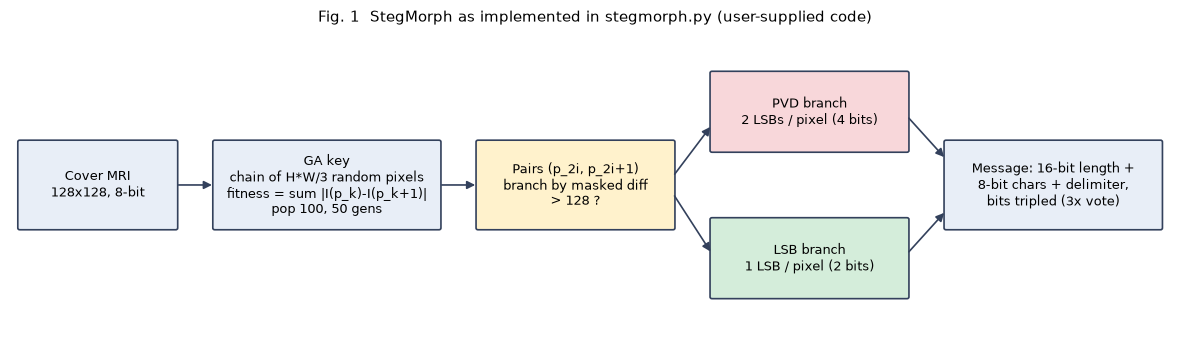

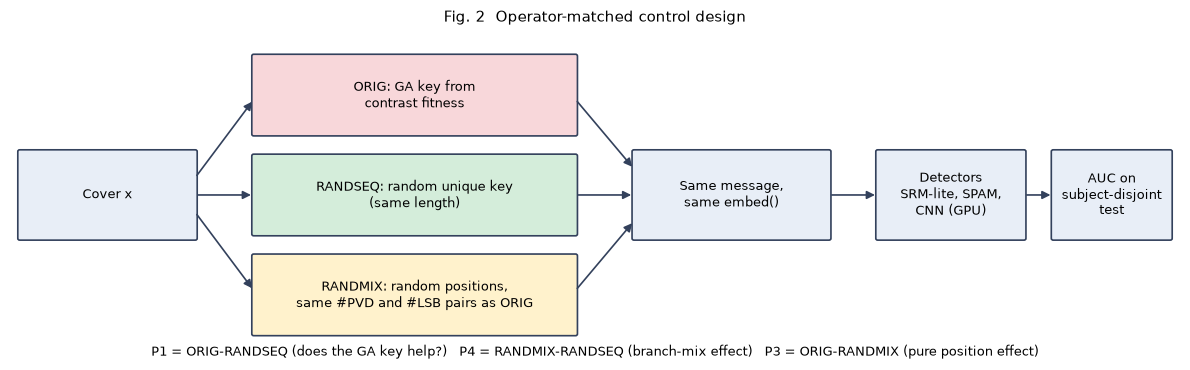

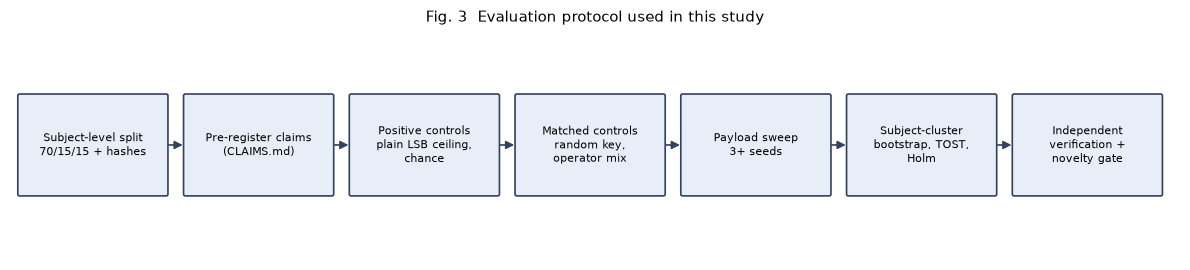

In [6]:
import matplotlib; import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
os.makedirs("results/figures", exist_ok=True)
def box(ax, x, y, w, h, t, fc="#e8eef7", fs=9):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02", fc=fc, ec="#33415c", lw=1.2)); ax.text(x+w/2, y+h/2, t, ha="center", va="center", fontsize=fs, wrap=True)
def arr(ax, a, b): ax.add_patch(FancyArrowPatch(a, b, arrowstyle="-|>", mutation_scale=12, color="#33415c", lw=1.2))
# Fig 1: StegMorph as implemented in stegmorph.py
fig, ax = plt.subplots(figsize=(12, 3.6)); ax.axis("off"); ax.set_xlim(0, 12); ax.set_ylim(0, 3.6)
box(ax, .1, 1.3, 1.6, 1, "Cover MRI\n128x128, 8-bit"); box(ax, 2.1, 1.3, 2.3, 1, "GA key\nchain of H*W/3 random pixels\nfitness = sum |I(p_k)-I(p_k+1)|\npop 100, 50 gens"); box(ax, 4.8, 1.3, 2.0, 1, "Pairs (p_2i, p_2i+1)\nbranch by masked diff\n> 128 ?", "#fff2cc")
box(ax, 7.2, 2.2, 2.0, .9, "PVD branch\n2 LSBs / pixel (4 bits)", "#f8d7da"); box(ax, 7.2, .5, 2.0, .9, "LSB branch\n1 LSB / pixel (2 bits)", "#d4edda"); box(ax, 9.6, 1.3, 2.2, 1, "Message: 16-bit length +\n8-bit chars + delimiter,\nbits tripled (3x vote)")
for a, b in [((1.7, 1.8), (2.1, 1.8)), ((4.4, 1.8), (4.8, 1.8)), ((6.8, 1.9), (7.2, 2.5)), ((6.8, 1.7), (7.2, 1.0)), ((9.2, 2.6), (9.6, 2.1)), ((9.2, 1.0), (9.6, 1.5))]: arr(ax, a, b)
ax.set_title("Fig. 1  StegMorph as implemented in stegmorph.py (user-supplied code)", fontsize=11); plt.tight_layout(); plt.savefig("results/figures/fig1_stegmorph_pipeline.png", dpi=200); plt.show()
# Fig 2: operator-matched control design
fig, ax = plt.subplots(figsize=(12, 3.8)); ax.axis("off"); ax.set_xlim(0, 12); ax.set_ylim(0, 3.8)
box(ax, .1, 1.4, 1.8, 1, "Cover x"); box(ax, 2.5, 2.6, 3.3, .9, "ORIG: GA key from\ncontrast fitness", "#f8d7da"); box(ax, 2.5, 1.45, 3.3, .9, "RANDSEQ: random unique key\n(same length)", "#d4edda"); box(ax, 2.5, .3, 3.3, .9, "RANDMIX: random positions,\nsame #PVD and #LSB pairs as ORIG", "#fff2cc")
box(ax, 6.4, 1.4, 2.0, 1, "Same message,\nsame embed()"); box(ax, 8.9, 1.4, 1.5, 1, "Detectors\nSRM-lite, SPAM,\nCNN (GPU)"); box(ax, 10.7, 1.4, 1.2, 1, "AUC on\nsubject-disjoint\ntest")
for a, b in [((1.9, 2.1), (2.5, 3.0)), ((1.9, 1.9), (2.5, 1.9)), ((1.9, 1.7), (2.5, .8)), ((5.8, 3.0), (6.4, 2.2)), ((5.8, 1.9), (6.4, 1.9)), ((5.8, .8), (6.4, 1.6)), ((8.4, 1.9), (8.9, 1.9)), ((10.4, 1.9), (10.7, 1.9))]: arr(ax, a, b)
ax.text(6, .05, "P1 = ORIG-RANDSEQ (does the GA key help?)   P4 = RANDMIX-RANDSEQ (branch-mix effect)   P3 = ORIG-RANDMIX (pure position effect)", ha="center", fontsize=9)
ax.set_title("Fig. 2  Operator-matched control design", fontsize=11); plt.tight_layout(); plt.savefig("results/figures/fig2_control_design.png", dpi=200); plt.show()
# Fig 3: evaluation protocol
fig, ax = plt.subplots(figsize=(12, 2.8)); ax.axis("off"); ax.set_xlim(0, 12); ax.set_ylim(0, 2.8)
steps = ["Subject-level split\n70/15/15 + hashes", "Pre-register claims\n(CLAIMS.md)", "Positive controls\nplain LSB ceiling,\nchance", "Matched controls\nrandom key,\noperator mix", "Payload sweep\n3+ seeds", "Subject-cluster\nbootstrap, TOST,\nHolm", "Independent\nverification +\nnovelty gate"]
for i, s in enumerate(steps):
    box(ax, .1+i*1.7, .8, 1.5, 1.2, s, fs=8)
    if i: arr(ax, (.1+i*1.7-.2, 1.4), (.1+i*1.7, 1.4))
ax.set_title("Fig. 3  Evaluation protocol used in this study", fontsize=11); plt.tight_layout(); plt.savefig("results/figures/fig3_protocol.png", dpi=200); plt.show()

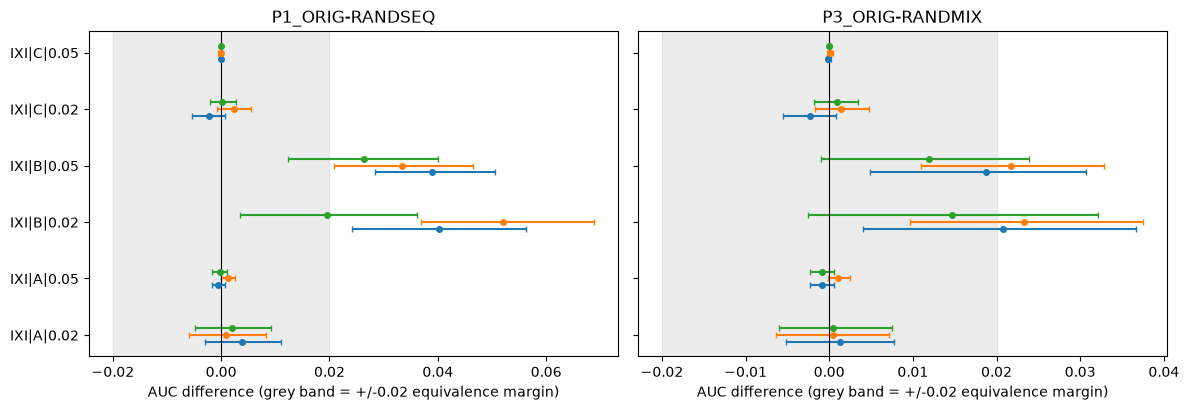

In [7]:
# Fig 4: forest plot of E11 contrasts (per-seed values + subject-bootstrap CI), built only from stored JSON
if R11:
    cells = sorted(R11); cons = ["P1_ORIG-RANDSEQ", "P3_ORIG-RANDMIX"]; fig, axs = plt.subplots(1, 2, figsize=(12, 0.45*len(cells)+1.5), sharey=True)
    for ax, c in zip(axs, cons):
        for yi, k in enumerate(cells):
            for s, v in R11[k]:
                d = v["contrasts"][c]; ax.errorbar(d["diff"], yi+0.12*(s-1), xerr=[[d["diff"]-d["ci95_subject_bootstrap"][0]], [d["ci95_subject_bootstrap"][1]-d["diff"]]], fmt="o", ms=4, capsize=2, color=f"C{s}")
        ax.axvline(0, color="k", lw=.8); ax.axvspan(-.02, .02, color="gray", alpha=.15); ax.set_title(c); ax.set_yticks(range(len(cells))); ax.set_yticklabels(cells); ax.set_xlabel("AUC difference (grey band = +/-0.02 equivalence margin)")
    plt.tight_layout(); plt.savefig("results/figures/fig4_e11_forest.png", dpi=200); plt.show()
else: print("no E11 results yet")

## 5. E12 (low payload), E13 (transfer) and E14 (cost-guided key) on the Mac GPU
All three were pre-registered in `state/CLAIMS.md` before the numbers were seen. Tables below are read from the stored JSON; nothing is typed in by hand.

In [8]:
R12 = load("results/e12/e11_seed*.json"); print("E12: payload 0.005 / 0.01 bpp, faithful StegMorph, IXI"); display(table(R12, ["P1_ORIG-RANDSEQ", "P4_RANDMIX-RANDSEQ", "P3_ORIG-RANDMIX"], "RANDSEQ"))
print("E12 verdicts (same rule as E11)"); display(pd.DataFrame([{"cell": k, "contrast": c, "verdict": verdict(L, c)} for k, L in sorted(R12.items()) for c in ["P1_ORIG-RANDSEQ", "P3_ORIG-RANDMIX"]]))
for scen in ["noHH", "noIOP", "oasis"]:
    R = load(f"results/e13/e13_{scen}_seed*.json"); print("E13 transfer, scenario", scen); display(table(R, ["P1_ORIG-RANDSEQ", "P3_ORIG-RANDMIX"], "RANDSEQ"))
    display(pd.DataFrame([{"cell": k, "contrast": c, "verdict": verdict(L, c)} for k, L in sorted(R.items()) for c in ["P1_ORIG-RANDSEQ", "P3_ORIG-RANDMIX"]]))

E12: payload 0.005 / 0.01 bpp, faithful StegMorph, IXI


,cell,n_seeds,AUC RANDSEQ,P1_ORIG-RANDSEQ,P4_RANDMIX-RANDSEQ,P3_ORIG-RANDMIX
0,IXI|A|0.005,3,0.6474,"+0.016 [+0.011,+0.022]","+0.014 [+0.011,+0.015]","+0.002 [-0.000,+0.008]"
1,IXI|A|0.01,3,0.7730,"+0.010 [+0.007,+0.013]","+0.014 [+0.013,+0.014]","-0.004 [-0.007,-0.000]"
2,IXI|B|0.005,3,0.5270,"+0.026 [+0.020,+0.033]","+0.014 [+0.004,+0.021]","+0.013 [+0.004,+0.029]"
3,IXI|B|0.01,3,0.5872,"+0.025 [+0.011,+0.034]","+0.010 [-0.000,+0.017]","+0.015 [+0.011,+0.017]"
4,IXI|C|0.005,3,0.7518,"+0.013 [+0.004,+0.022]","+0.017 [+0.014,+0.019]","-0.004 [-0.010,+0.005]"
5,IXI|C|0.01,3,0.8868,"+0.007 [+0.001,+0.011]","+0.008 [+0.004,+0.014]","-0.001 [-0.005,+0.005]"


E12 verdicts (same rule as E11)


,cell,contrast,verdict
0,IXI|A|0.005,P1_ORIG-RANDSEQ,INCONCLUSIVE
1,IXI|A|0.005,P3_ORIG-RANDMIX,EQUIVALENT within +/-0.02 (mean per-seed CI bo...
2,IXI|A|0.01,P1_ORIG-RANDSEQ,EQUIVALENT within +/-0.02 (mean per-seed CI bo...
3,IXI|A|0.01,P3_ORIG-RANDMIX,EQUIVALENT within +/-0.02 (mean per-seed CI bo...
4,IXI|B|0.005,P1_ORIG-RANDSEQ,EFFECT (+): ORIG more detectable
5,IXI|B|0.005,P3_ORIG-RANDMIX,INCONCLUSIVE
6,IXI|B|0.01,P1_ORIG-RANDSEQ,INCONCLUSIVE
7,IXI|B|0.01,P3_ORIG-RANDMIX,INCONCLUSIVE
8,IXI|C|0.005,P1_ORIG-RANDSEQ,INCONCLUSIVE
9,IXI|C|0.005,P3_ORIG-RANDMIX,EQUIVALENT within +/-0.02 (mean per-seed CI bo...


E13 transfer, scenario noHH


,cell,n_seeds,AUC RANDSEQ,P1_ORIG-RANDSEQ,P3_ORIG-RANDMIX
0,noHH|A|0.01,3,0.7599,"-0.005 [-0.015,+0.002]","-0.018 [-0.022,-0.014]"
1,noHH|B|0.01,3,0.5788,"+0.059 [+0.039,+0.075]","+0.018 [-0.002,+0.056]"
2,noHH|C|0.01,3,0.9198,"+0.014 [+0.010,+0.020]","+0.003 [-0.005,+0.008]"


... (3 outputs left out)

,cell,contrast,verdict
0,noIOP|A|0.01,P1_ORIG-RANDSEQ,INCONCLUSIVE
1,noIOP|A|0.01,P3_ORIG-RANDMIX,INCONCLUSIVE
2,noIOP|B|0.01,P1_ORIG-RANDSEQ,INCONCLUSIVE
3,noIOP|B|0.01,P3_ORIG-RANDMIX,INCONCLUSIVE
4,noIOP|C|0.01,P1_ORIG-RANDSEQ,INCONCLUSIVE
5,noIOP|C|0.01,P3_ORIG-RANDMIX,INCONCLUSIVE


E13 transfer, scenario oasis


,cell,n_seeds,AUC RANDSEQ,P1_ORIG-RANDSEQ,P3_ORIG-RANDMIX
0,oasis|A|0.01,3,0.8387,"-0.035 [-0.068,-0.004]","-0.009 [-0.061,+0.026]"
1,oasis|B|0.01,3,0.5156,"-0.007 [-0.013,-0.003]","-0.002 [-0.013,+0.016]"
2,oasis|C|0.01,3,0.4655,"+0.010 [-0.018,+0.055]","-0.014 [-0.094,+0.069]"


,cell,contrast,verdict
0,oasis|A|0.01,P1_ORIG-RANDSEQ,INCONCLUSIVE
1,oasis|A|0.01,P3_ORIG-RANDMIX,INCONCLUSIVE
2,oasis|B|0.01,P1_ORIG-RANDSEQ,INCONCLUSIVE
3,oasis|B|0.01,P3_ORIG-RANDMIX,INCONCLUSIVE
4,oasis|C|0.01,P1_ORIG-RANDSEQ,EQUIVALENT within +/-0.02 (mean per-seed CI bo...
5,oasis|C|0.01,P3_ORIG-RANDMIX,INCONCLUSIVE


In [9]:
R14 = load("results/e14/e14_seed*.json"); C14 = ["P1_ORIG-RANDSEQ", "Q1_COSTKEY-RANDSEQ", "Q2_COSTKEY-COSTMIX", "Q3_COSTMIX-RANDSEQ", "B1_HILL-RANDSEQ"]
print("E14: cost-guided key (COSTKEY), operator-matched control (COSTMIX) and a real adaptive embedder (HILL, simulated)"); display(table(R14, C14, "RANDSEQ"))
def v14(L, c):
    d = [v["contrasts"][c]["diff"] for _, v in L]; hi = [v["contrasts"][c]["ci95_subject_bootstrap"][1] for _, v in L]
    return "MET (all seeds, diff<-0.02, CI high<0)" if len(L) == 3 and all(x < -0.02 for x in d) and all(h < 0 for h in hi) else "not met"
display(pd.DataFrame([{"cell": k, "contrast": c, "pre-registered rule": v14(L, c)} for k, L in sorted(R14.items()) for c in ["Q1_COSTKEY-RANDSEQ", "Q2_COSTKEY-COSTMIX"]]))
print("Reading: the rule is met for detector A (SRM-lite) only; the CNN (C) shows no gain.")

E14: cost-guided key (COSTKEY), operator-matched control (COSTMIX) and a real adaptive embedder (HILL, simulated)


,cell,n_seeds,AUC RANDSEQ,P1_ORIG-RANDSEQ,Q1_COSTKEY-RANDSEQ,Q2_COSTKEY-COSTMIX,Q3_COSTMIX-RANDSEQ,B1_HILL-RANDSEQ
0,IXI|A|0.01,3,0.7701,"+0.016 [+0.014,+0.019]","-0.145 [-0.149,-0.142]","-0.148 [-0.151,-0.145]","+0.003 [-0.004,+0.007]","-0.237 [-0.239,-0.233]"
1,IXI|A|0.02,3,0.9092,"+0.003 [+0.000,+0.006]","-0.183 [-0.185,-0.181]","-0.185 [-0.188,-0.181]","+0.002 [-0.000,+0.004]","-0.341 [-0.342,-0.340]"
2,IXI|B|0.01,3,0.5915,"+0.022 [+0.011,+0.032]","-0.025 [-0.027,-0.022]","-0.024 [-0.030,-0.018]","-0.001 [-0.010,+0.009]","-0.055 [-0.064,-0.043]"
3,IXI|B|0.02,3,0.6658,"+0.036 [+0.032,+0.039]","-0.028 [-0.037,-0.017]","-0.048 [-0.051,-0.043]","+0.020 [+0.014,+0.025]","-0.088 [-0.094,-0.084]"
4,IXI|C|0.01,3,0.8873,"+0.004 [+0.003,+0.006]","+0.014 [+0.010,+0.018]","+0.003 [-0.006,+0.010]","+0.011 [+0.005,+0.019]","-0.306 [-0.309,-0.302]"
5,IXI|C|0.02,3,0.9746,"-0.002 [-0.003,+0.000]","+0.005 [+0.002,+0.007]","+0.003 [+0.001,+0.005]","+0.002 [-0.001,+0.004]","-0.288 [-0.292,-0.282]"


,cell,contrast,pre-registered rule
0,IXI|A|0.01,Q1_COSTKEY-RANDSEQ,"MET (all seeds, diff<-0.02, CI high<0)"
1,IXI|A|0.01,Q2_COSTKEY-COSTMIX,"MET (all seeds, diff<-0.02, CI high<0)"
2,IXI|A|0.02,Q1_COSTKEY-RANDSEQ,"MET (all seeds, diff<-0.02, CI high<0)"
3,IXI|A|0.02,Q2_COSTKEY-COSTMIX,"MET (all seeds, diff<-0.02, CI high<0)"
4,IXI|B|0.01,Q1_COSTKEY-RANDSEQ,"MET (all seeds, diff<-0.02, CI high<0)"
5,IXI|B|0.01,Q2_COSTKEY-COSTMIX,not met
6,IXI|B|0.02,Q1_COSTKEY-RANDSEQ,not met
7,IXI|B|0.02,Q2_COSTKEY-COSTMIX,"MET (all seeds, diff<-0.02, CI high<0)"
8,IXI|C|0.01,Q1_COSTKEY-RANDSEQ,not met
9,IXI|C|0.01,Q2_COSTKEY-COSTMIX,not met


Reading: the rule is met for detector A (SRM-lite) only; the CNN (C) shows no gain.


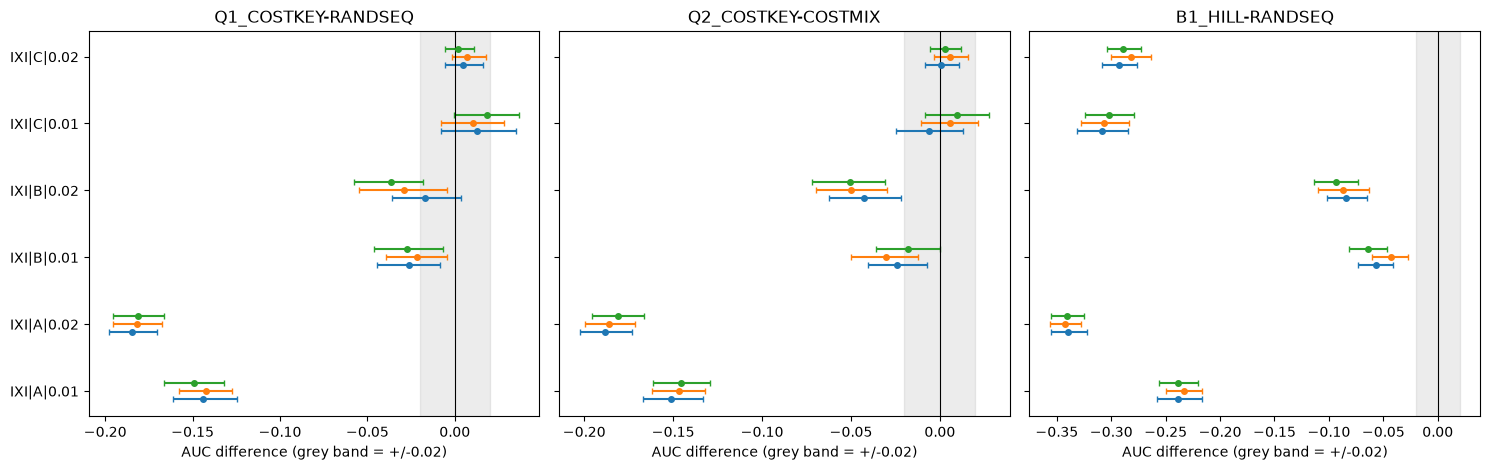

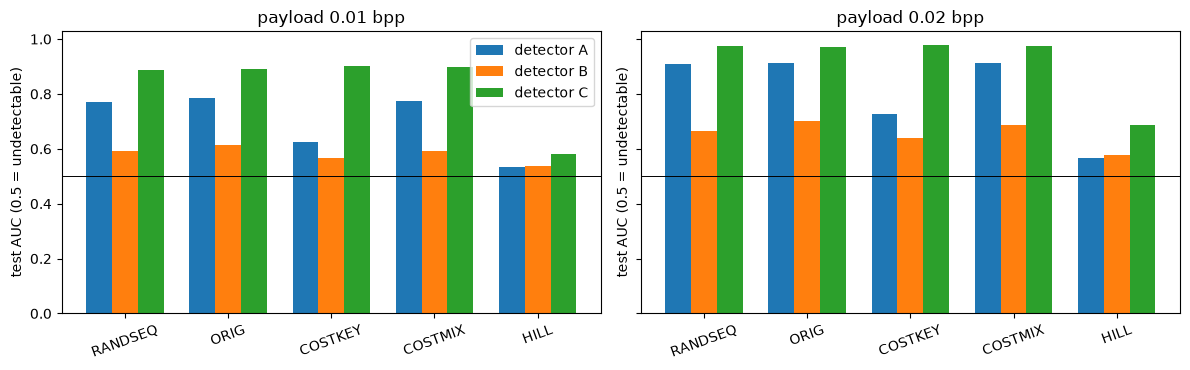

In [10]:
# Fig 5: E14 forest plot, per detector, built from stored JSON
cells = sorted(R14); cons = ["Q1_COSTKEY-RANDSEQ", "Q2_COSTKEY-COSTMIX", "B1_HILL-RANDSEQ"]; fig, axs = plt.subplots(1, 3, figsize=(15, 0.5*len(cells)+1.8), sharey=True)
for ax, c in zip(axs, cons):
    for yi, k in enumerate(cells):
        for s, v in R14[k]:
            d = v["contrasts"][c]; ax.errorbar(d["diff"], yi+0.12*(s-1), xerr=[[d["diff"]-d["ci95_subject_bootstrap"][0]], [d["ci95_subject_bootstrap"][1]-d["diff"]]], fmt="o", ms=4, capsize=2, color=f"C{s}")
    ax.axvline(0, color="k", lw=.8); ax.axvspan(-.02, .02, color="gray", alpha=.15); ax.set_title(c); ax.set_yticks(range(len(cells))); ax.set_yticklabels(cells); ax.set_xlabel("AUC difference (grey band = +/-0.02)")
plt.tight_layout(); plt.savefig("results/figures/fig5_e14_forest.png", dpi=200); plt.show()
# Fig 6: detectability by scheme, mean over seeds
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, bpp in zip(axs, ["0.01", "0.02"]):
    w = 0.25
    for j, fam in enumerate("ABC"):
        L = R14.get(f"IXI|{fam}|{bpp}", [])
        if not L: continue
        sch = ["RANDSEQ", "ORIG", "COSTKEY", "COSTMIX", "HILL"]; ax.bar(np.arange(5)+j*w, [np.mean([v["auc"][x] for _, v in L]) for x in sch], w, label=f"detector {fam}")
    ax.set_xticks(np.arange(5)+w); ax.set_xticklabels(sch, rotation=20); ax.axhline(0.5, color="k", lw=.7); ax.set_title(f"payload {bpp} bpp"); ax.set_ylabel("test AUC (0.5 = undetectable)")
axs[0].legend(); plt.tight_layout(); plt.savefig("results/figures/fig6_e14_auc_by_scheme.png", dpi=200); plt.show()

## 6. Verification follow-ups: E16 (full-data CNN), E17 (stronger SRM classifier), E18 (smooth-region control), Holm v2
All pre-registered in `state/CLAIMS.md` before running. E16 to E18 JSON files are named `e14_seed*.json` inside their folders because the script was reused.

In [11]:
def q(folder, con, bases=None):
    R = load(f"results/{folder}/e14_seed*.json"); rows = []
    for k, L in sorted(R.items()):
        x = [v["contrasts"][con]["diff"] for _, v in L]; hi = [v["contrasts"][con]["ci95_subject_bootstrap"][1] for _, v in L]; lo = [v["contrasts"][con]["ci95_subject_bootstrap"][0] for _, v in L]
        rows.append({"cell": k, "seeds": len(L), con: f"{np.mean(x):+.3f} [{min(x):+.3f},{max(x):+.3f}]", "all CI high<0": all(h < 0 for h in hi), "all CI low>0": all(l > 0 for l in lo)})
    return pd.DataFrame(rows)
print("E16: CNN on all 5239 training slices, 30 epochs (pre-registered: null survives if Q1 >= -0.02 in all seeds)"); display(q("e16", "Q1_COSTKEY-RANDSEQ"))
print("E17: SRM-lite features + boosted trees (detector D); gain survives if Q1 < -0.02 with CI high < 0 in all seeds"); display(q("e17", "Q1_COSTKEY-RANDSEQ"))
print("E18: smooth-region key (highest-cost third), Q4 = ANTIKEY - RANDSEQ; dose-response if > +0.02 with CI low > 0"); display(q("e18", "Q1_ANTIKEY-RANDSEQ"))

E16: CNN on all 5239 training slices, 30 epochs (pre-registered: null survives if Q1 >= -0.02 in all seeds)


,cell,seeds,Q1_COSTKEY-RANDSEQ,all CI high<0,all CI low>0
0,IXI|C|0.01,3,"+0.010 [+0.006,+0.013]",False,False


E17: SRM-lite features + boosted trees (detector D); gain survives if Q1 < -0.02 with CI high < 0 in all seeds


,cell,seeds,Q1_COSTKEY-RANDSEQ,all CI high<0,all CI low>0
0,IXI|D|0.01,3,"-0.211 [-0.218,-0.205]",True,False
1,IXI|D|0.02,3,"-0.211 [-0.217,-0.201]",True,False


E18: smooth-region key (highest-cost third), Q4 = ANTIKEY - RANDSEQ; dose-response if > +0.02 with CI low > 0


,cell,seeds,Q1_ANTIKEY-RANDSEQ,all CI high<0,all CI low>0
0,IXI|A|0.01,3,"+0.126 [+0.121,+0.132]",False,True
1,IXI|A|0.02,3,"+0.066 [+0.064,+0.068]",False,True
2,IXI|D|0.01,3,"+0.125 [+0.119,+0.130]",False,True
3,IXI|D|0.02,3,"+0.057 [+0.054,+0.059]",False,True


In [12]:
H = json.load(open("results/holm/holm_v2.json")); df = pd.DataFrame(H); df["differs"] = df.p_holm < .05; df["equivalent"] = df.p_tost_holm < .05
print("Holm v2 (SE = sqrt(bootstrap SE^2 + between-seed SD^2); 30 primary tests):", int(df.differs.sum()), "differences,", int(df.equivalent.sum()), "equivalences survive"); display(df[["exp", "cell", "contrast", "diff", "se", "p_holm", "differs", "p_tost_holm", "equivalent"]].round(4))

Holm v2 (SE = sqrt(bootstrap SE^2 + between-seed SD^2); 30 primary tests): 5 differences, 7 equivalences survive


,exp,cell,contrast,diff,se,p_holm,differs,p_tost_holm,equivalent
0,E11,IXI|A|0.02,P1_ORIG-RANDSEQ,0.0022,0.0050,1.0000,False,0.0049,True
1,E11,IXI|A|0.05,P1_ORIG-RANDSEQ,0.0002,0.0050,1.0000,False,0.0010,True
2,E11,IXI|B|0.02,P1_ORIG-RANDSEQ,0.0373,0.0184,0.8927,False,1.0000,False
3,E11,IXI|B|0.05,P1_ORIG-RANDSEQ,0.0329,0.0090,0.0075,True,1.0000,False
4,E11,IXI|C|0.02,P1_ORIG-RANDSEQ,0.0001,0.0050,1.0000,False,0.0010,True
5,E11,IXI|C|0.05,P1_ORIG-RANDSEQ,-0.0000,0.0050,1.0000,False,0.0010,True
6,E12,IXI|A|0.005,P1_ORIG-RANDSEQ,0.0162,0.0069,0.4267,False,1.0000,False
7,E12,IXI|B|0.005,P1_ORIG-RANDSEQ,0.0265,0.0100,0.2039,False,1.0000,False
8,E12,IXI|C|0.005,P1_ORIG-RANDSEQ,0.0131,0.0107,1.0000,False,1.0000,False
9,E13,noHH|A|0.01,P1_ORIG-RANDSEQ,-0.0054,0.0118,1.0000,False,1.0000,False


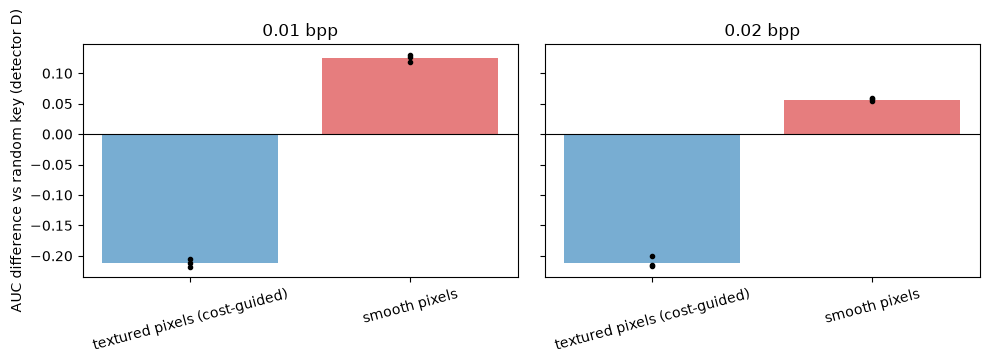

In [13]:
# Fig 7: dose-response of key position on SRM-lite detectability (detector D), mean over seeds, with per-seed points
fig, axs = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, bpp in zip(axs, ["0.01", "0.02"]):
    for lab, folder, con, col in [("textured pixels (cost-guided)", "e17", "Q1_COSTKEY-RANDSEQ", "C0"), ("smooth pixels", "e18", "Q1_ANTIKEY-RANDSEQ", "C3")]:
        L = load(f"results/{folder}/e14_seed*.json")[f"IXI|D|{bpp}"]; y = [v["contrasts"][con]["diff"] for _, v in L]
        ax.bar(lab, np.mean(y), color=col, alpha=.6); ax.plot([lab]*len(y), y, "k.")
    ax.axhline(0, color="k", lw=.8); ax.set_title(f"{bpp} bpp"); ax.tick_params(axis="x", rotation=15)
axs[0].set_ylabel("AUC difference vs random key (detector D)"); plt.tight_layout(); plt.savefig("results/figures/fig7_dose_response.png", dpi=200); plt.show()

## 7. Second collection and closing checks: E19 (OASIS), E20 (non-HILL texture key), E21 (CNN at 0.02 bpp), E22 (CNN learning curve), E23 (refit-aware bootstrap)
All pre-registered in `state/CLAIMS.md` before running; outcomes logged there. Result JSON files are named `e14_seed*.json` (script reuse) except E23 (`e23_seed0.json`).

In [14]:
print("E19 OASIS, cost-guided key (Q1 = COSTKEY - RANDSEQ); detectors A, B, C, D; note near-saturated AUC for A, C, D"); display(q("e19_oasis_cost", "Q1_COSTKEY-RANDSEQ"))
print("E19 OASIS, GA key (P1 = ORIG - RANDSEQ)"); display(q("e19_oasis_cost", "P1_ORIG-RANDSEQ"))
print("E19 OASIS, smooth key (Q4 = ANTIKEY - RANDSEQ), detectors A and D"); display(q("e19_oasis_anti", "Q1_ANTIKEY-RANDSEQ"))

E19 OASIS, cost-guided key (Q1 = COSTKEY - RANDSEQ); detectors A, B, C, D; note near-saturated AUC for A, C, D


,cell,seeds,Q1_COSTKEY-RANDSEQ,all CI high<0,all CI low>0
0,OASIS|A|0.01,3,"-0.006 [-0.007,-0.004]",True,False
1,OASIS|A|0.02,3,"+0.000 [+0.000,+0.000]",False,False
2,OASIS|B|0.01,3,"-0.093 [-0.108,-0.079]",True,False
3,OASIS|B|0.02,3,"-0.162 [-0.170,-0.150]",True,False
4,OASIS|C|0.01,3,"+0.000 [-0.000,+0.000]",False,False
5,OASIS|C|0.02,3,"+0.000 [+0.000,+0.000]",False,False
6,OASIS|D|0.01,3,"-0.008 [-0.009,-0.007]",True,False
7,OASIS|D|0.02,3,"-0.000 [-0.000,-0.000]",False,False


E19 OASIS, GA key (P1 = ORIG - RANDSEQ)


,cell,seeds,P1_ORIG-RANDSEQ,all CI high<0,all CI low>0
0,OASIS|A|0.01,3,"-0.000 [-0.001,+0.001]",False,False
1,OASIS|A|0.02,3,"+0.000 [+0.000,+0.000]",False,False
2,OASIS|B|0.01,3,"-0.009 [-0.017,+0.001]",False,False
3,OASIS|B|0.02,3,"+0.000 [-0.004,+0.005]",False,False
4,OASIS|C|0.01,3,"-0.000 [-0.000,+0.000]",False,False
5,OASIS|C|0.02,3,"+0.000 [-0.000,+0.000]",False,False
6,OASIS|D|0.01,3,"-0.001 [-0.001,+0.001]",False,False
7,OASIS|D|0.02,3,"+0.000 [+0.000,+0.000]",False,False


E19 OASIS, smooth key (Q4 = ANTIKEY - RANDSEQ), detectors A and D


,cell,seeds,Q1_ANTIKEY-RANDSEQ,all CI high<0,all CI low>0
0,OASIS|A|0.01,3,"+0.003 [+0.002,+0.003]",False,True
1,OASIS|A|0.02,3,"+0.000 [+0.000,+0.000]",False,False
2,OASIS|D|0.01,3,"+0.004 [+0.002,+0.005]",False,False
3,OASIS|D|0.02,3,"+0.000 [+0.000,+0.000]",False,False


In [15]:
print("E20: non-HILL texture key (highest 3x3 local-std third); H20a: Q1 < -0.02 with CI high < 0"); display(q("e20", "Q1_COSTKEY-RANDSEQ"))
print("E20 matched control Q3 = COSTMIX - RANDSEQ (H20b: |Q3| < 0.02)"); display(q("e20", "Q3_COSTMIX-RANDSEQ"))
print("E21: CNN at 0.02 bpp, all training slices, 30 epochs (H21: Q1 >= -0.02 on all seeds)"); display(q("e21", "Q1_COSTKEY-RANDSEQ"))

E20: non-HILL texture key (highest 3x3 local-std third); H20a: Q1 < -0.02 with CI high < 0


,cell,seeds,Q1_COSTKEY-RANDSEQ,all CI high<0,all CI low>0
0,IXI|A|0.01,3,"-0.102 [-0.107,-0.097]",True,False
1,IXI|A|0.02,3,"-0.115 [-0.117,-0.112]",True,False
2,IXI|D|0.01,3,"-0.157 [-0.162,-0.148]",True,False
3,IXI|D|0.02,3,"-0.127 [-0.141,-0.118]",True,False


E20 matched control Q3 = COSTMIX - RANDSEQ (H20b: |Q3| < 0.02)


,cell,seeds,Q3_COSTMIX-RANDSEQ,all CI high<0,all CI low>0
0,IXI|A|0.01,3,"+0.008 [+0.003,+0.013]",False,False
1,IXI|A|0.02,3,"+0.001 [-0.000,+0.003]",False,False
2,IXI|D|0.01,3,"+0.014 [+0.011,+0.019]",False,True
3,IXI|D|0.02,3,"+0.007 [+0.006,+0.009]",False,False


E21: CNN at 0.02 bpp, all training slices, 30 epochs (H21: Q1 >= -0.02 on all seeds)


,cell,seeds,Q1_COSTKEY-RANDSEQ,all CI high<0,all CI low>0
0,IXI|C|0.02,3,"+0.006 [+0.003,+0.008]",False,False


In [16]:
rows = []
for lab, folder in [("1000", "e22_n1000"), ("2500", "e22_n2500"), ("5239 (E16)", "e16")]:
    L = load(f"results/{folder}/e14_seed*.json")["IXI|C|0.01"]; y = [v["contrasts"]["Q1_COSTKEY-RANDSEQ"]["diff"] for _, v in L]; a = [v["auc"]["RANDSEQ"] for _, v in L]
    rows.append({"training slices": lab, "Q1(C) mean": round(float(np.mean(y)), 3), "per seed": [round(float(v), 3) for v in y], "random-key AUC": round(float(np.mean(a)), 3)})
print("E22: CNN learning curve at 0.01 bpp (H22: Q1 more negative with fewer slices -> not supported)"); display(pd.DataFrame(rows))
E23 = json.load(open("results/e23/e23_seed0.json"))["results"]
print("E23: bootstrap resampling training and test subjects and refitting detector A (200 replicates, seed 0)")
display(pd.DataFrame([{"cell": k, "contrast": c, "mean": x["mean"], "ci95": x["ci95"]} for k, v in E23.items() for c, x in v["contrasts"].items()]))

E22: CNN learning curve at 0.01 bpp (H22: Q1 more negative with fewer slices -> not supported)


,training slices,Q1(C) mean,per seed,random-key AUC
0,1000,0.016,"[0.017, 0.001, 0.03]",0.851
1,2500,0.015,"[0.019, 0.01, 0.016]",0.887
2,5239 (E16),0.010,"[0.013, 0.006, 0.011]",0.910


E23: bootstrap resampling training and test subjects and refitting detector A (200 replicates, seed 0)


,cell,contrast,mean,ci95
0,IXI|A|0.01,P1_ORIG-RANDSEQ,0.0130,"[-0.0005, 0.0277]"
1,IXI|A|0.01,Q1_COSTKEY-RANDSEQ,-0.1416,"[-0.1583, -0.1239]"
2,IXI|A|0.01,Q3_COSTMIX-RANDSEQ,0.0052,"[-0.0079, 0.0186]"
3,IXI|A|0.02,P1_ORIG-RANDSEQ,0.0063,"[-0.0047, 0.0179]"
4,IXI|A|0.02,Q1_COSTKEY-RANDSEQ,-0.1945,"[-0.2092, -0.1787]"
5,IXI|A|0.02,Q3_COSTMIX-RANDSEQ,0.0037,"[-0.0078, 0.0134]"


## 8. Review round of 13 Nov 2026: E24 to E35
Pre-registered in `state/CLAIMS.md` (entries E24-E34, E26 amendments, E34b, E35) before the runs. Result folders `results/e24` ... `results/e35` use the JSON layout of `code/summarize.py` (`e24_seed*.json` in every folder because the driver `code/exp24.py` is shared). Every seed draws 80% of the training subjects. Real HILL and S-UNIWARD = reference simulators in Octave (`code/octave`).

In [17]:
from summarize import agg
def show(folder, ds, cons, dets="AD", bpps=(0.01, 0.02)):
    A = agg(folder); rows = []
    for bpp in bpps:
        for det in dets:
            if (ds, det, bpp) not in A: continue
            o = A[(ds, det, bpp)]
            for c in cons:
                if c in o["con"]: v = o["con"][c]; rows.append({"bpp": bpp, "det": det, "contrast": c, "mean": round(v["mean"], 3), "range": (round(v["lo"], 3), round(v["hi"], 3)), "random-key AUC": round(o["auc"]["RANDSEQ"][0], 3)})
    return pd.DataFrame(rows)
print("E24/E25 (IXI T2, real HILL and S-UNIWARD, detector S = selection-channel-aware)"); display(show("e24", "ixi", ["ORIG-RANDSEQ", "COSTKEY-RANDSEQ", "COSTMIX-RANDSEQ", "ANTIKEY-RANDSEQ", "HILLR-RANDSEQ", "SUNIR-RANDSEQ", "HILLSIM-RANDSEQ"], dets="ABDS"))
print("HILL validation on 200 slices"); print(open("results/hill_validation_200.json").read())
print("GA statistics"); print(open("results/ga_stats.json").read())

E24/E25 (IXI T2, real HILL and S-UNIWARD, detector S = selection-channel-aware)


,bpp,det,contrast,mean,range,random-key AUC
0,0.01,A,ORIG-RANDSEQ,0.008,"(0.005, 0.01)",0.769
1,0.01,A,COSTKEY-RANDSEQ,-0.151,"(-0.157, -0.145)",0.769
2,0.01,A,COSTMIX-RANDSEQ,-0.001,"(-0.003, 0.001)",0.769
3,0.01,A,ANTIKEY-RANDSEQ,0.123,"(0.122, 0.124)",0.769
4,0.01,A,HILLR-RANDSEQ,-0.237,"(-0.241, -0.233)",0.769
5,0.01,A,SUNIR-RANDSEQ,-0.221,"(-0.227, -0.217)",0.769
6,0.01,A,HILLSIM-RANDSEQ,-0.239,"(-0.242, -0.237)",0.769
7,0.01,B,ORIG-RANDSEQ,0.029,"(0.014, 0.043)",0.585
8,0.01,B,COSTKEY-RANDSEQ,-0.003,"(-0.02, 0.009)",0.585
9,0.01,B,COSTMIX-RANDSEQ,0.015,"(0.007, 0.022)",0.585


HILL validation on 200 slices
{
 "0.01": {
  "changed_octave": 0.00362762451171875,
  "changed_numpy": 0.00364654541015625,
  "ratio": 1.0052157819466643,
  "per_slice_corr": 0.37811645018140083,
  "prob_map_max_abs_diff": 1.1814572609673835e-05,
  "expected_changes_corr": 0.9999999999989895
 },
 "0.02": {
  "changed_octave": 0.0080413818359375,
  "changed_numpy": 0.008062744140625,
  "ratio": 1.0026565464895636,
  "per_slice_corr": 0.5524022200395602,
  "prob_map_max_abs_diff": 1.6923171204830112e-05,
  "expected_changes_corr": 0.9999999999990716
 }
}
GA statistics
{
 "contrast_gain": {
  "mean": 1.118539509615221,
  "sd": 0.027641984171263706
 },
 "len_ratio": {
  "mean": 0.8493003663003661,
  "sd": 0.003998582515282031
 },
 "tex_share": {
  "mean": 0.3428786352518903,
  "sd": 0.007087543963373673
 },
 "cost_ratio": {
  "mean": 1.076346395794176,
  "sd": 0.13515470494651904
 }
}


In [18]:
print("E27: IXI T1 (NIfTI)"); display(show("e27", "ixit1", ["ORIG-RANDSEQ", "COSTKEY-RANDSEQ", "ANTIKEY-RANDSEQ", "HILLR-RANDSEQ"], dets="ABDS"))
print("E32: CT (OrganAMNIST)"); display(show("e32", "ct", ["ORIG-RANDSEQ", "COSTKEY-RANDSEQ", "HILLR-RANDSEQ"]))
print("E34/E34b/E35: 256x256 (E34 same bpp; E34b same number of bits; E35 foreground-restricted keys)")
display(show("e34", "ixi256", ["ORIG-RANDSEQ", "COSTKEY-RANDSEQ", "HILLR-RANDSEQ"])); display(show("e34b", "ixi256", ["ORIG-RANDSEQ", "COSTKEY-RANDSEQ"], bpps=(0.0025, 0.005))); display(show("e35", "ixi256", ["RANDFG-RANDSEQ", "COSTFG-RANDFG", "ANTIFG-RANDFG", "M:COSTFG-RANDFG"], bpps=(0.0025, 0.005)))

E27: IXI T1 (NIfTI)


,bpp,det,contrast,mean,range,random-key AUC
0,0.01,A,ORIG-RANDSEQ,0.006,"(0.001, 0.012)",0.605
1,0.01,A,COSTKEY-RANDSEQ,-0.073,"(-0.075, -0.07)",0.605
2,0.01,A,ANTIKEY-RANDSEQ,0.082,"(0.074, 0.089)",0.605
3,0.01,A,HILLR-RANDSEQ,-0.095,"(-0.097, -0.093)",0.605
4,0.01,B,ORIG-RANDSEQ,-0.003,"(-0.004, -0.003)",0.527
5,0.01,B,COSTKEY-RANDSEQ,-0.000,"(-0.009, 0.005)",0.527
6,0.01,B,ANTIKEY-RANDSEQ,0.076,"(0.071, 0.082)",0.527
7,0.01,B,HILLR-RANDSEQ,-0.023,"(-0.034, -0.016)",0.527
8,0.01,D,ORIG-RANDSEQ,0.018,"(0.016, 0.019)",0.604
9,0.01,D,COSTKEY-RANDSEQ,-0.093,"(-0.108, -0.084)",0.604


E32: CT (OrganAMNIST)


,bpp,det,contrast,mean,range,random-key AUC
0,0.01,A,ORIG-RANDSEQ,0.001,"(0.0, 0.001)",0.996
1,0.01,A,COSTKEY-RANDSEQ,-0.028,"(-0.029, -0.027)",0.996
2,0.01,A,HILLR-RANDSEQ,-0.189,"(-0.191, -0.186)",0.996
3,0.01,D,ORIG-RANDSEQ,0.000,"(0.0, 0.001)",0.998
4,0.01,D,COSTKEY-RANDSEQ,-0.020,"(-0.021, -0.019)",0.998
5,0.01,D,HILLR-RANDSEQ,-0.102,"(-0.106, -0.1)",0.998
6,0.02,A,ORIG-RANDSEQ,0.000,"(0.0, 0.001)",0.998
7,0.02,A,COSTKEY-RANDSEQ,-0.013,"(-0.014, -0.013)",0.998
8,0.02,A,HILLR-RANDSEQ,-0.089,"(-0.09, -0.087)",0.998
9,0.02,D,ORIG-RANDSEQ,0.000,"(0.0, 0.0)",1.000


E34/E34b/E35: 256x256 (E34 same bpp; E34b same number of bits; E35 foreground-restricted keys)


,bpp,det,contrast,mean,range,random-key AUC
0,0.01,A,ORIG-RANDSEQ,0.000,"(0.0, 0.0)",1.0
1,0.01,A,COSTKEY-RANDSEQ,-0.157,"(-0.157, -0.157)",1.0
2,0.01,A,HILLR-RANDSEQ,-0.456,"(-0.458, -0.453)",1.0
3,0.01,D,ORIG-RANDSEQ,0.000,"(0.0, 0.0)",1.0
4,0.01,D,COSTKEY-RANDSEQ,-0.184,"(-0.188, -0.18)",1.0
5,0.01,D,HILLR-RANDSEQ,-0.491,"(-0.498, -0.483)",1.0
6,0.02,A,ORIG-RANDSEQ,0.000,"(0.0, 0.0)",1.0
7,0.02,A,COSTKEY-RANDSEQ,-0.035,"(-0.036, -0.033)",1.0
8,0.02,A,HILLR-RANDSEQ,-0.391,"(-0.393, -0.39)",1.0
9,0.02,D,ORIG-RANDSEQ,0.000,"(0.0, 0.0)",1.0


,bpp,det,contrast,mean,range,random-key AUC
0,0.0025,A,ORIG-RANDSEQ,0.000,"(0.0, 0.0)",0.998
1,0.0025,A,COSTKEY-RANDSEQ,-0.399,"(-0.4, -0.399)",0.998
2,0.0025,D,ORIG-RANDSEQ,-0.000,"(-0.001, -0.0)",0.999
3,0.0025,D,COSTKEY-RANDSEQ,-0.439,"(-0.44, -0.438)",0.999
4,0.0050,A,ORIG-RANDSEQ,0.000,"(0.0, 0.0)",1.000
5,0.0050,A,COSTKEY-RANDSEQ,-0.308,"(-0.311, -0.305)",1.000
6,0.0050,D,ORIG-RANDSEQ,0.000,"(0.0, 0.0)",1.000
7,0.0050,D,COSTKEY-RANDSEQ,-0.334,"(-0.34, -0.328)",1.000


,bpp,det,contrast,mean,range,random-key AUC
0,0.0025,A,RANDFG-RANDSEQ,-0.364,"(-0.367, -0.362)",0.998
1,0.0025,A,COSTFG-RANDFG,-0.081,"(-0.083, -0.079)",0.998
2,0.0025,A,ANTIFG-RANDFG,0.100,"(0.099, 0.101)",0.998
3,0.0025,A,M:COSTFG-RANDFG,0.008,"(0.007, 0.009)",0.998
4,0.0025,D,RANDFG-RANDSEQ,-0.410,"(-0.42, -0.399)",0.999
5,0.0025,D,COSTFG-RANDFG,-0.065,"(-0.091, -0.039)",0.999
6,0.0025,D,ANTIFG-RANDFG,0.109,"(0.102, 0.116)",0.999
7,0.0025,D,M:COSTFG-RANDFG,0.011,"(-0.006, 0.029)",0.999
8,0.0050,A,RANDFG-RANDSEQ,-0.242,"(-0.245, -0.24)",1.000
9,0.0050,A,COSTFG-RANDFG,-0.146,"(-0.149, -0.144)",1.000


In [19]:
print("E28: cost maps and dose-response (contrast vs RANDSEQ)"); display(show("e28", "ixi", [k for k in agg("e28")[("ixi", "A", 0.01)]["con"] if k.endswith("-RANDSEQ")]))
print("E29: payload sweep"); display(show("e29", "ixi", ["ORIG-RANDSEQ", "COSTKEY-RANDSEQ", "ANTIKEY-RANDSEQ", "HILLR-RANDSEQ", "SUNIR-RANDSEQ"], bpps=(0.01, 0.02, 0.05, 0.09)))
print("E30: GA objective and other embedders"); display(show("e30", "ixi", [k for k in agg("e30")[("ixi", "A", 0.01)]["con"]]))

E28: cost maps and dose-response (contrast vs RANDSEQ)


,bpp,det,contrast,mean,range,random-key AUC
0,0.01,A,COSTKEY-RANDSEQ,-0.151,"(-0.157, -0.145)",0.769
1,0.01,A,ANTIKEY-RANDSEQ,0.123,"(0.122, 0.124)",0.769
2,0.01,A,K:hill:t:0.1-RANDSEQ,-0.160,"(-0.167, -0.156)",0.769
3,0.01,A,K:hill:t:0.2-RANDSEQ,-0.156,"(-0.16, -0.153)",0.769
4,0.01,A,K:hill:t:0.5-RANDSEQ,-0.135,"(-0.144, -0.13)",0.769
...,...,...,...,...,...,...
67,0.02,D,K:grad:s:0.33-RANDSEQ,0.047,"(0.042, 0.051)",0.919
68,0.02,D,K:ent:t:0.33-RANDSEQ,-0.183,"(-0.188, -0.178)",0.919
69,0.02,D,K:ent:s:0.33-RANDSEQ,0.056,"(0.052, 0.058)",0.919
70,0.02,D,K:suni:t:0.33-RANDSEQ,-0.126,"(-0.132, -0.12)",0.919


E29: payload sweep


,bpp,det,contrast,mean,range,random-key AUC
0,0.01,A,ORIG-RANDSEQ,0.008,"(0.005, 0.01)",0.769
1,0.01,A,COSTKEY-RANDSEQ,-0.151,"(-0.157, -0.145)",0.769
2,0.01,A,ANTIKEY-RANDSEQ,0.123,"(0.122, 0.124)",0.769
3,0.01,A,HILLR-RANDSEQ,-0.237,"(-0.241, -0.233)",0.769
4,0.01,A,SUNIR-RANDSEQ,-0.221,"(-0.227, -0.217)",0.769
5,0.01,D,ORIG-RANDSEQ,0.012,"(0.007, 0.017)",0.795
6,0.01,D,COSTKEY-RANDSEQ,-0.184,"(-0.188, -0.177)",0.795
7,0.01,D,ANTIKEY-RANDSEQ,0.117,"(0.114, 0.123)",0.795
8,0.01,D,HILLR-RANDSEQ,-0.276,"(-0.289, -0.264)",0.795
9,0.01,D,SUNIR-RANDSEQ,-0.259,"(-0.263, -0.256)",0.795


E30: GA objective and other embedders


,bpp,det,contrast,mean,range,random-key AUC
0,0.01,A,ORIG-RANDSEQ,0.008,"(0.005, 0.01)",0.769
1,0.01,A,GAMIN-RANDSEQ,-0.027,"(-0.034, -0.021)",0.769
2,0.01,A,GAMINS-RANDSEQ,-0.053,"(-0.058, -0.049)",0.769
3,0.01,A,COSTKEY-RANDSEQ,-0.151,"(-0.157, -0.145)",0.769
4,0.01,A,LSBK:C-LSBK:R,-0.147,"(-0.151, -0.139)",0.769
5,0.01,A,LSBK:A-LSBK:R,0.098,"(0.096, 0.099)",0.769
6,0.01,A,LSBM:C-LSBM:R,-0.149,"(-0.153, -0.143)",0.769
7,0.01,A,LSBM:A-LSBM:R,0.098,"(0.097, 0.098)",0.769
8,0.01,D,ORIG-RANDSEQ,0.012,"(0.007, 0.017)",0.795
9,0.01,D,GAMIN-RANDSEQ,-0.029,"(-0.035, -0.021)",0.795


In [20]:
print("E26: CNN training budget and contrasts"); print(json.dumps(json.load(open("results/e26/e26_summary.json")), indent=1)); print(open("Overleaf/article/tables/tab_budget.tex").read())
print("E33 change-reversal"); print(open("results/e26/e33_mechanism.json").read())
import glob as _g
for f in sorted(_g.glob("results/e31/e31_*.json")): print(f); print(open(f).read())

E26: CNN training budget and contrasts
{
 "net|COSTKEY|0": {
  "diff": 0.0083,
  "ci95": [
   -0.0101,
   0.0273
  ],
  "auc": 0.9217,
  "rand_auc": 0.9134
 },
 "net|COSTKEY|1": {
  "diff": 0.0113,
  "ci95": [
   -0.006,
   0.0311
  ],
  "auc": 0.9188,
  "rand_auc": 0.9075
 },
 "net|HILLR|0": {
  "diff": -0.3108,
  "ci95": [
   -0.3289,
   -0.291
  ],
  "auc": 0.6026,
  "rand_auc": 0.9134
 },
 "net|ORIG|0": {
  "diff": -0.0031,
  "ci95": [
   -0.0115,
   0.0056
  ],
  "auc": 0.9104,
  "rand_auc": 0.9134
 }
}
\begin{tabular}{llcrrrrr}
\toprule
Network & Key & Seed & Params (M) & Epochs run/best & Minutes & Val AUC & Test AUC \\
\midrule
Residual CNN & COSTKEY & 0 & 0.60 & 60/51 & 37 & 0.932 & 0.922 \\
Residual CNN & COSTKEY & 1 & 0.60 & 60/40 & 33 & 0.928 & 0.919 \\
Residual CNN & HILLR & 0 & 0.60 & 60/44 & 49 & 0.621 & 0.603 \\
Residual CNN & ORIG & 0 & 0.60 & 60/51 & 50 & 0.917 & 0.910 \\
Residual CNN & RANDSEQ & 0 & 0.60 & 60/55 & 39 & 0.912 & 0.913 \\
Residual CNN & RANDSEQ & 1 & 0.

fig_selection_maps


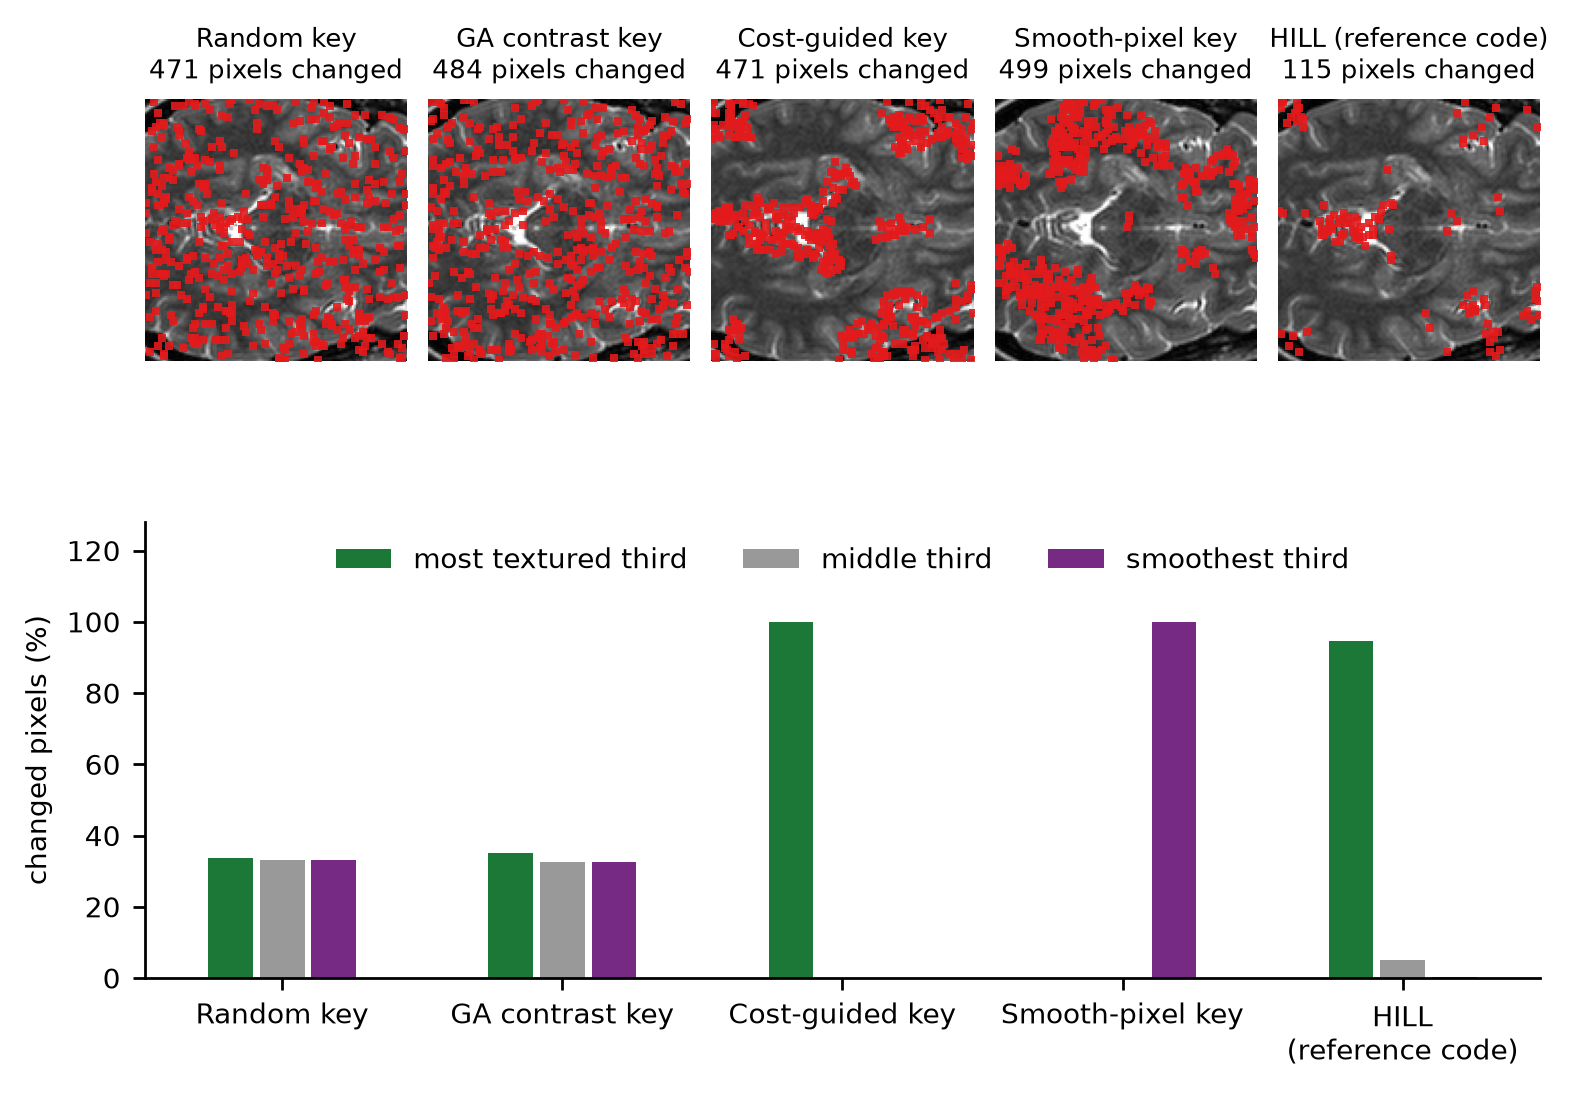

fig_heatmap


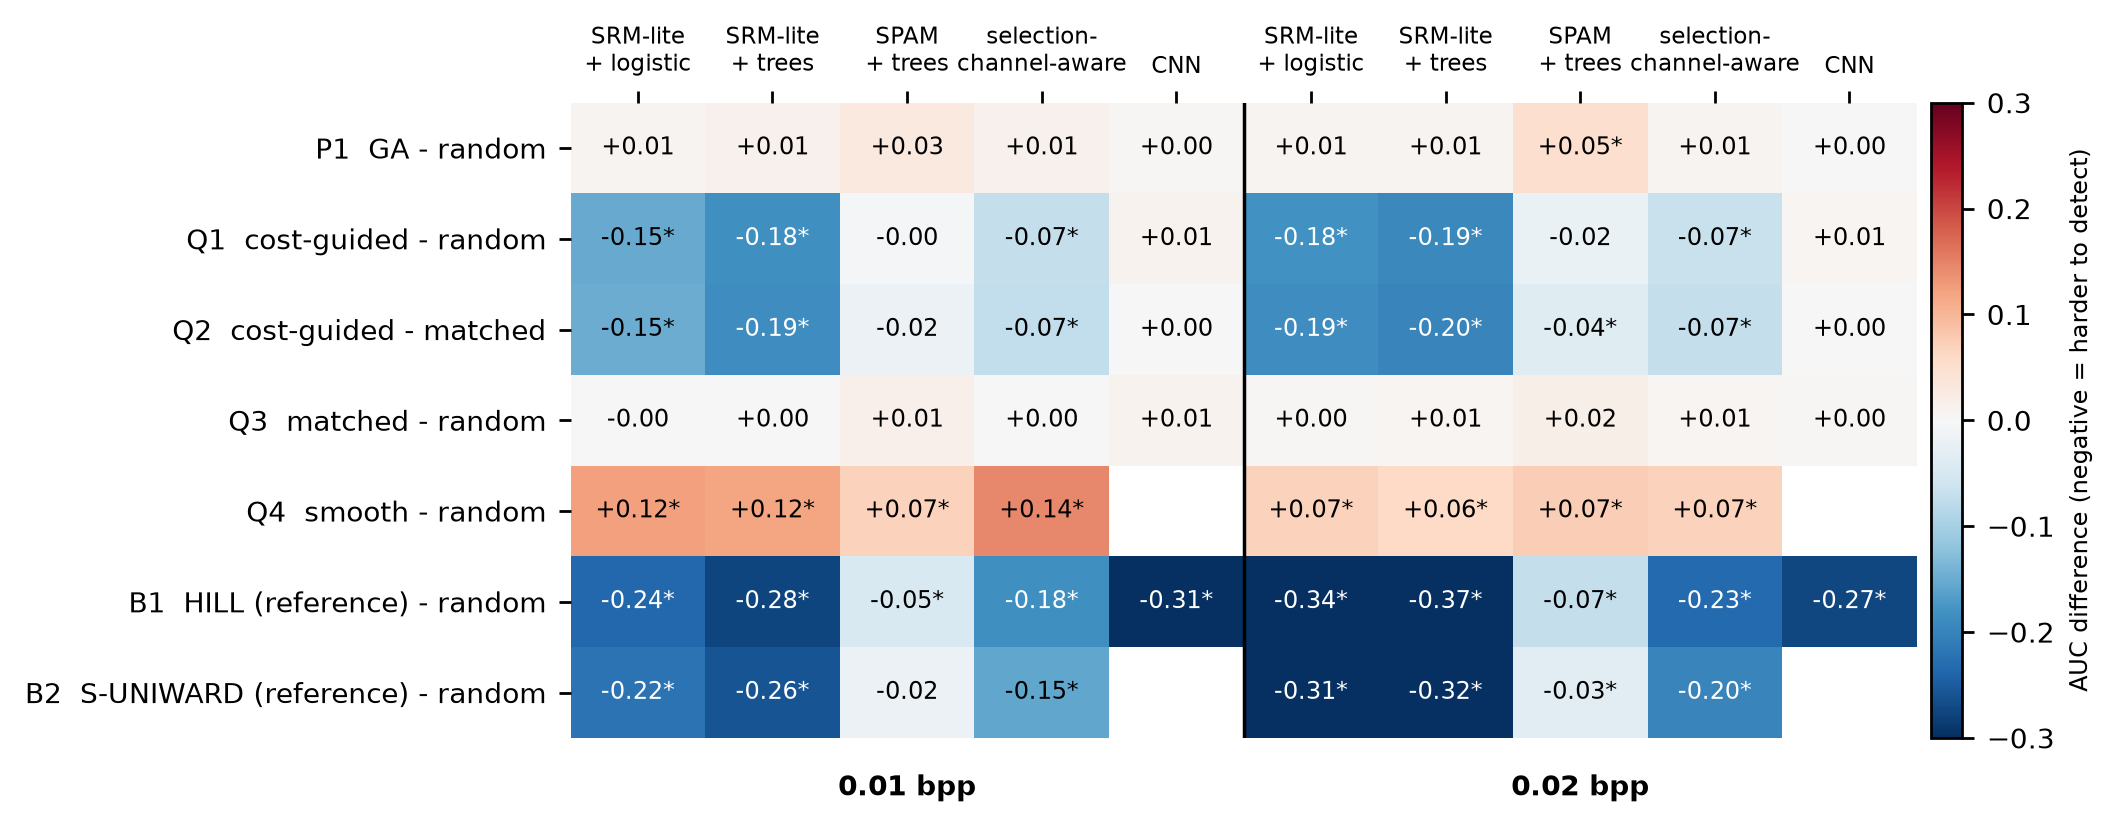

fig_roc


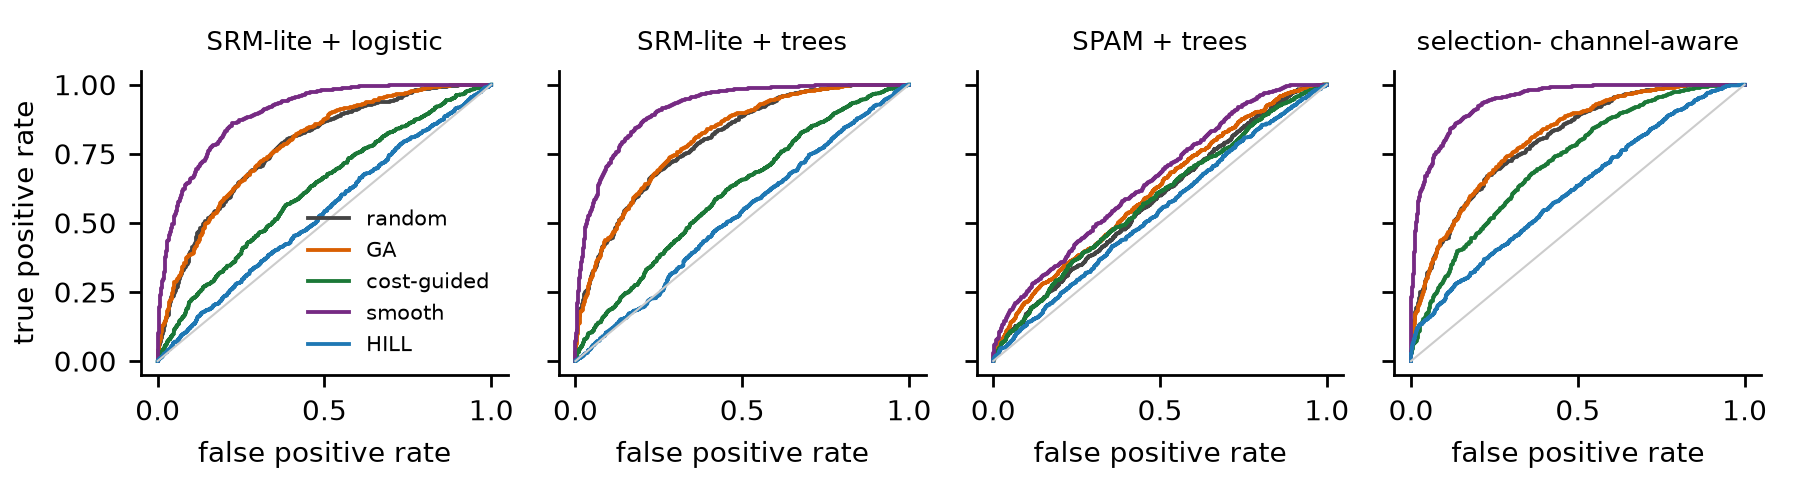

fig_dose


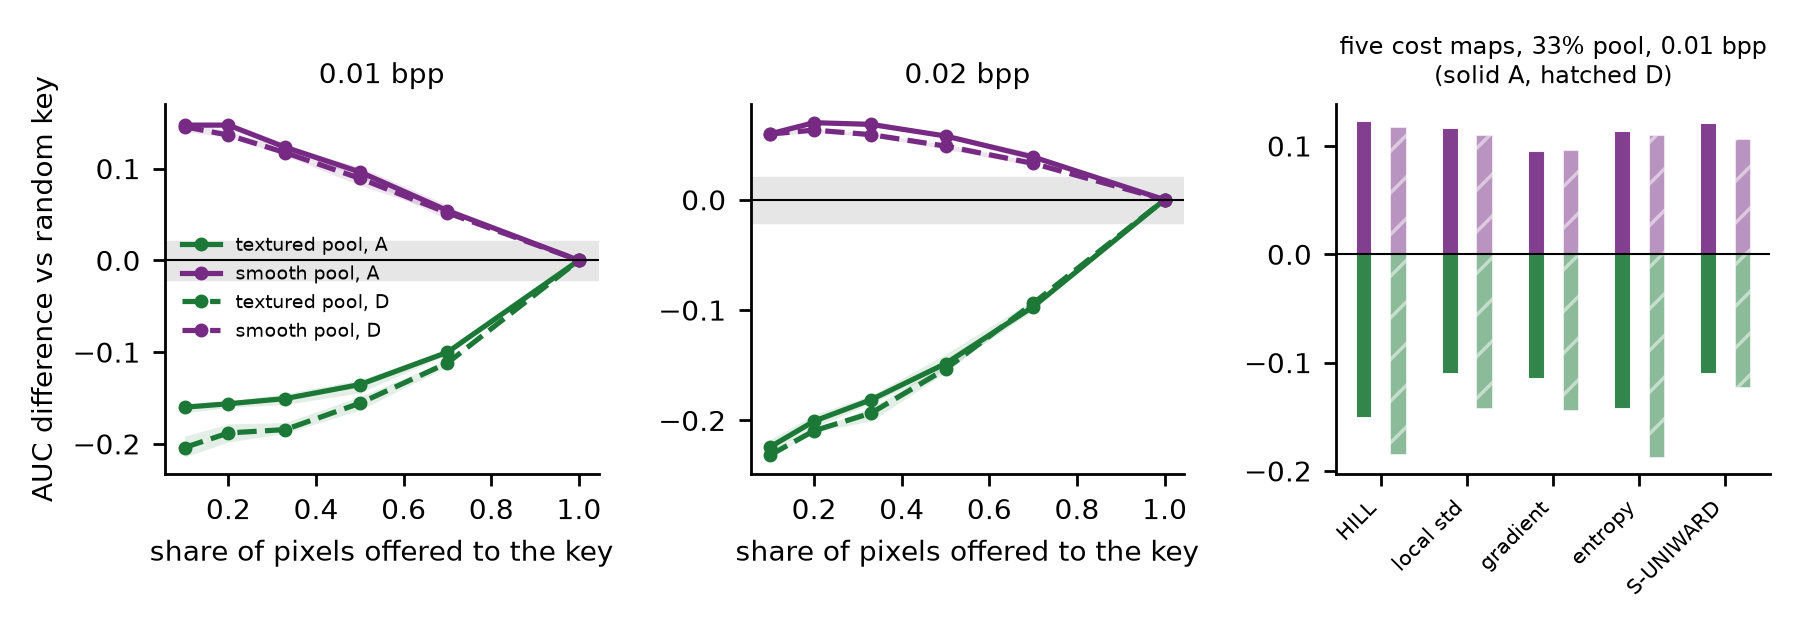

fig_payload


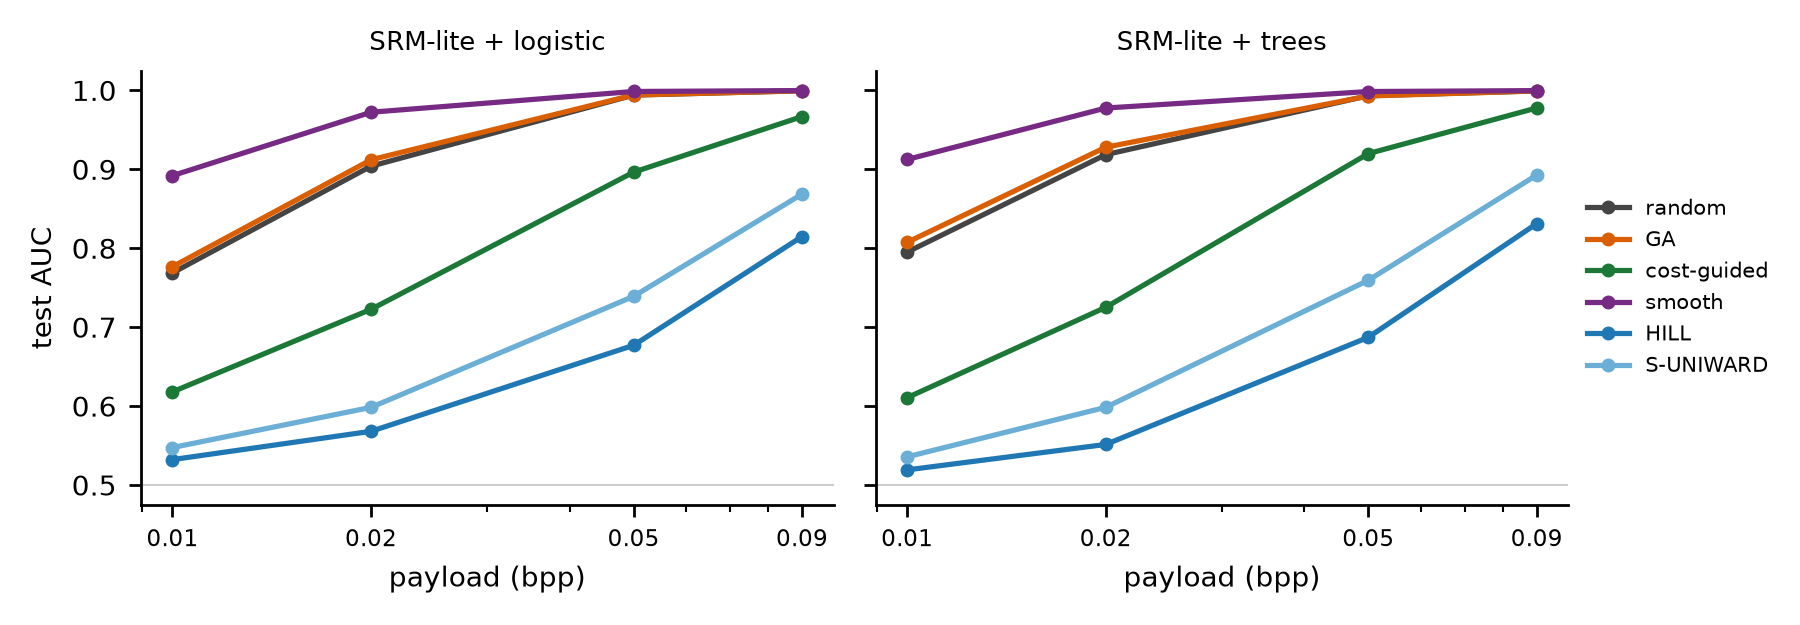

fig_change


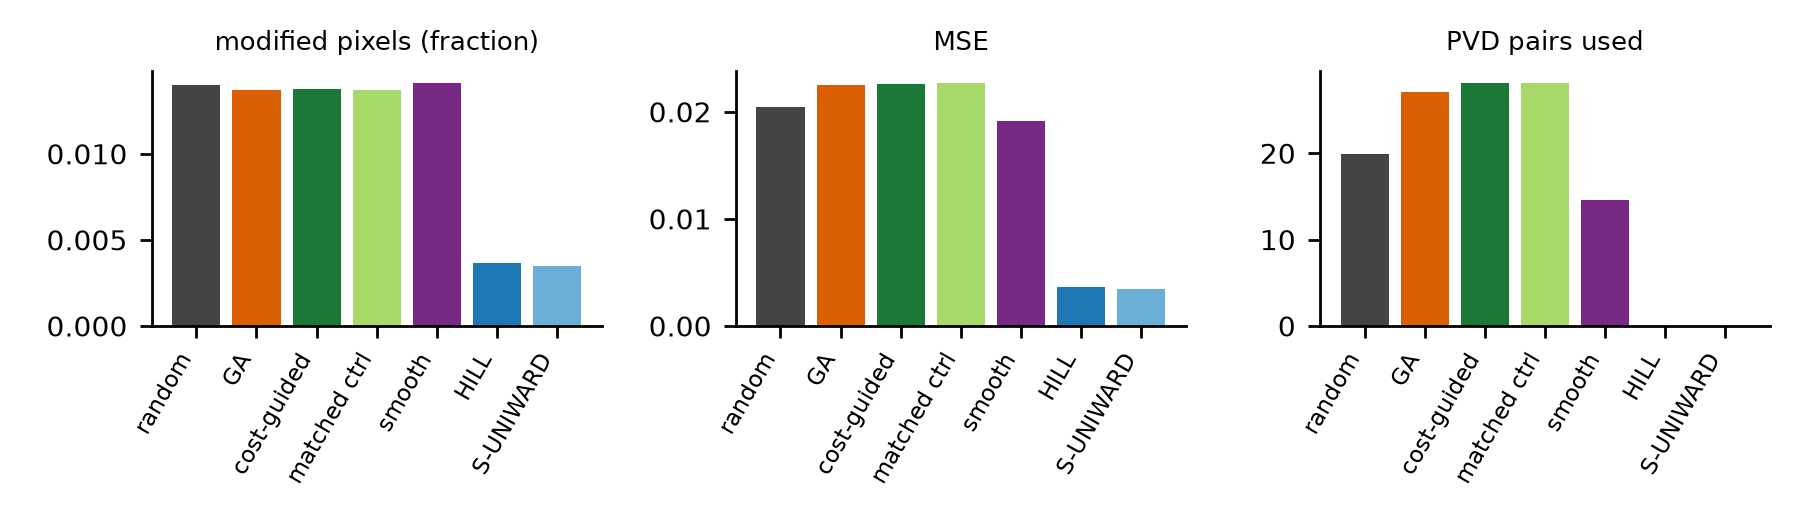

fig_hill


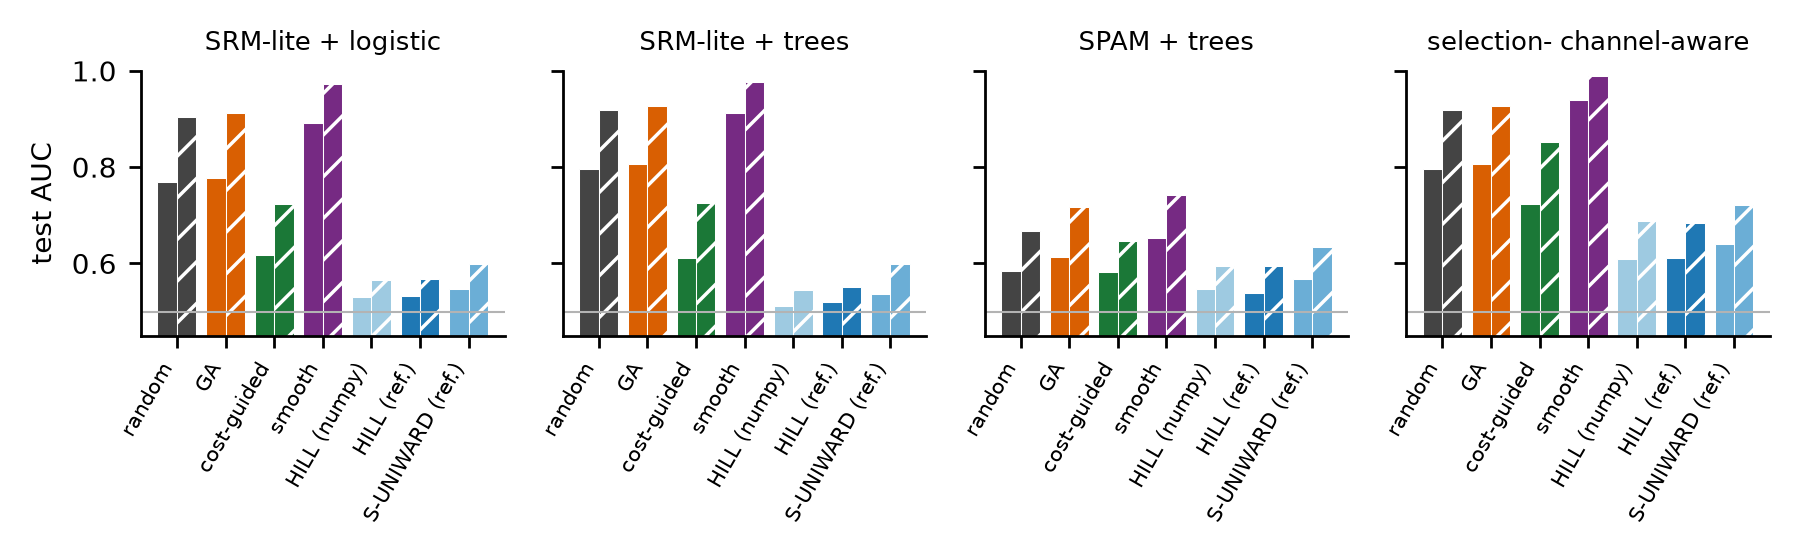

fig_saturation


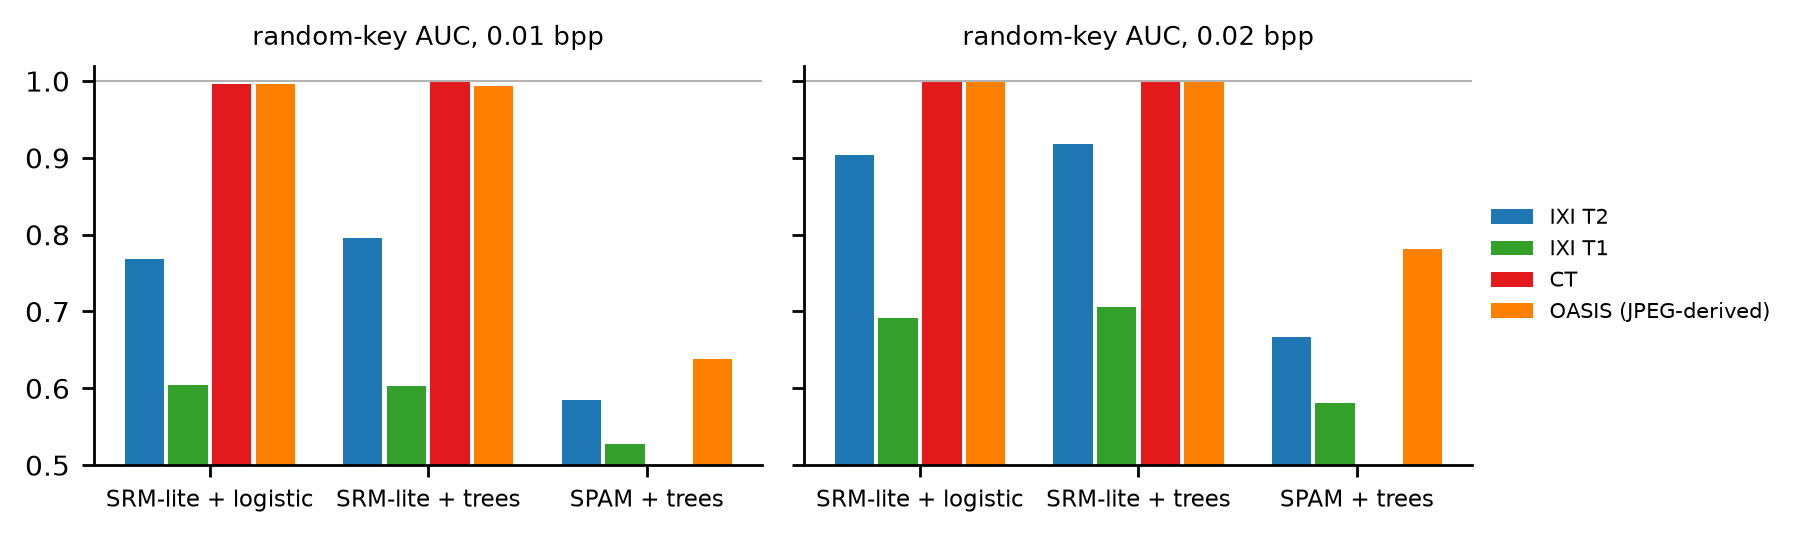

fig_protocol


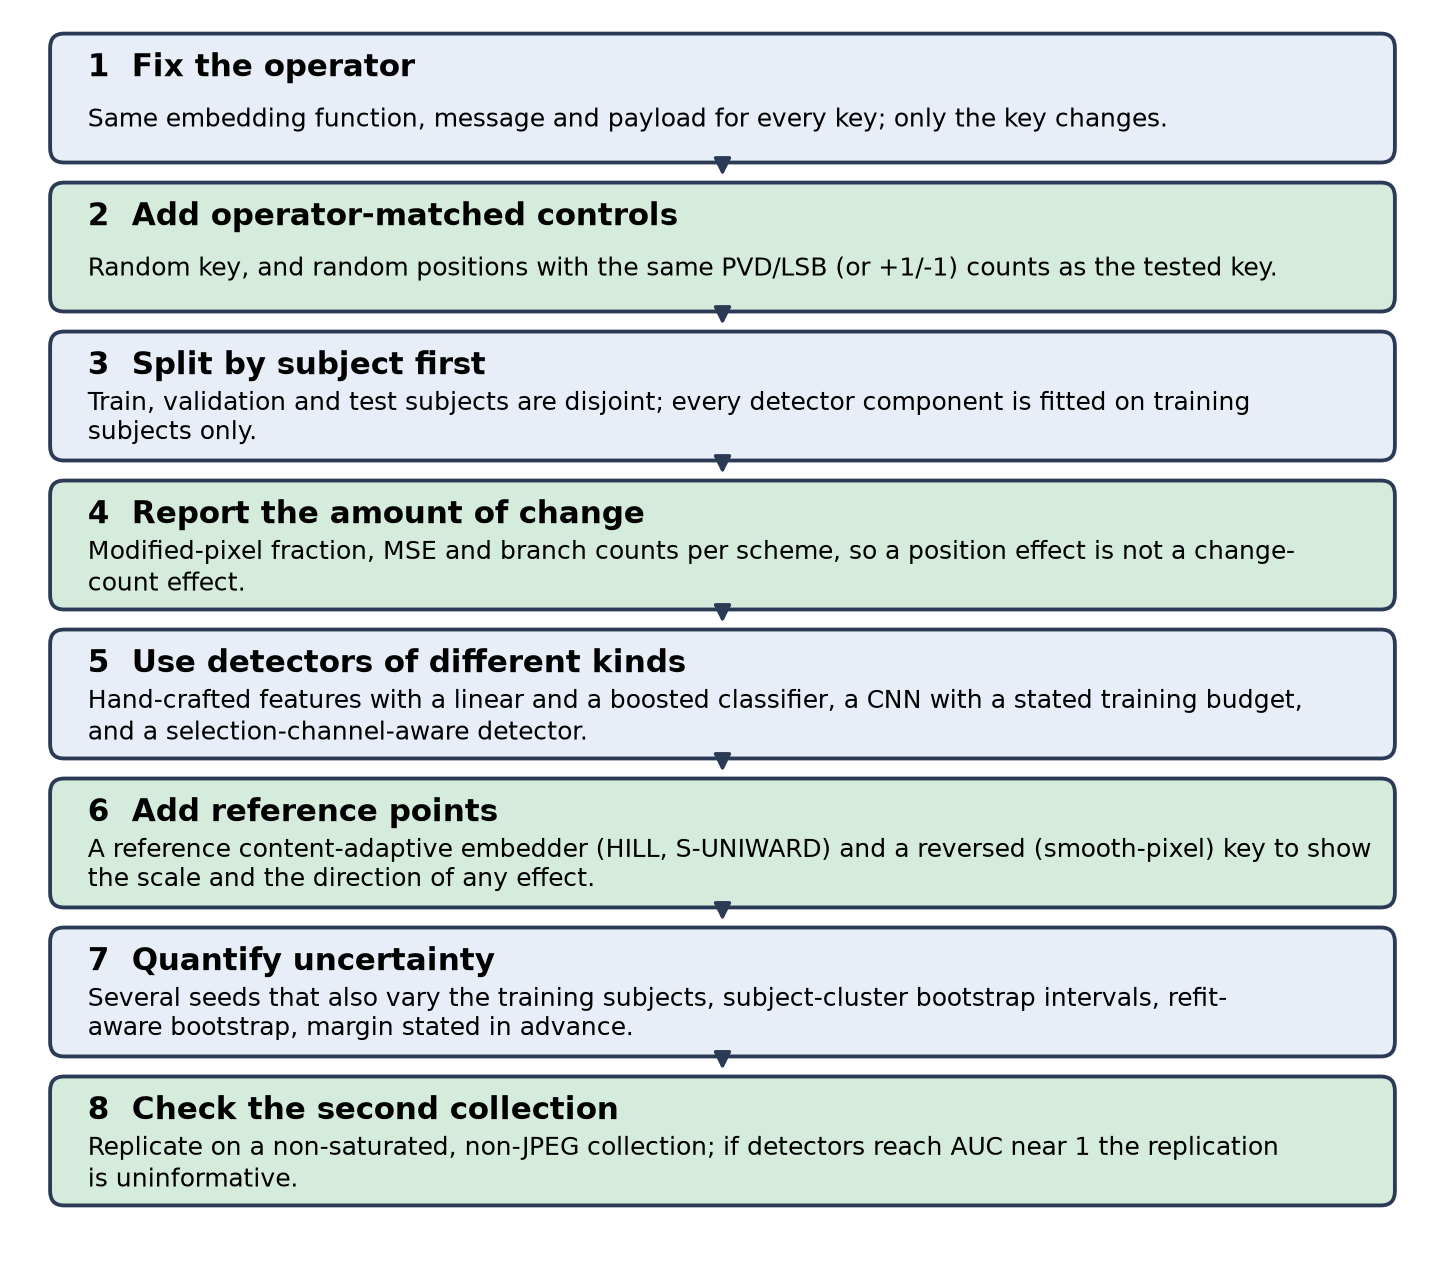

In [21]:
from IPython.display import Image, display as _d
for f in ["fig_selection_maps", "fig_heatmap", "fig_roc", "fig_dose", "fig_payload", "fig_change", "fig_hill", "fig_saturation", "fig_protocol", "fig_cnn_curve"]:
    if os.path.exists(f"Overleaf/article/figures/{f}.png"): print(f); _d(Image(f"Overleaf/article/figures/{f}.png", width=900))